In [9]:
import os
os.environ["XLA_FLAGS"] = "--xla_force_host_platform_device_count=10"

# os.environ["XLA_PYTHON_CLIENT_ALLOCATOR"] = "platform" 
# This makes JAX allocate exactly what is needed on demand, and deallocate memory that is no longer needed (note that this is the only configuration that will deallocate GPU memory, instead of reusing it). This is very slow, so is not recommended for general use, but may be useful for running with the minimal possible GPU memory footprint or debugging OOM failures.

os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = ".95"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import jax
import jax.numpy as jnp
from jax import random
import jax.numpy as jnp
from jax import random
import numpy as np
import matplotlib.pyplot as plt
from flax import linen as nn
import optax
import jax
import jax.numpy as jnp
from jax import random, jit
import optax
from tqdm import tqdm
import matplotlib.pyplot as plt
# Assuming equivalent JAX implementations
from src.subspace_curve import CategorySubspaceBatchNorm, pytree_to_matrix
import wandb
from src.models import ResNet, ResNetBlock, init_t_lambda_to_phi, init_model_tube, init_model_phi
from jax_tqdm import scan_tqdm
from torch.utils.data import random_split
import torch
import torchvision
from torch.utils.data import TensorDataset
import pandas as pd


%load_ext autoreload
%autoreload 2

# %env XLA_FLAGS="--xla_force_host_platform_device_count=10"
# os.environ["XLA_FLAGS"] = "--xla_force_host_platform_device_count=10"
# os.environ["XLA_FLAGS"] = ('--xla_force_host_platform_device_count=10 '
#                            '--xla_dump_to=xla_dump/')
%env XLA_FLAGS

#jax.devices("gpu")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


'--xla_force_host_platform_device_count=10'

### Data preperation 

In [2]:
def load_cifar10(seed=0):
    PATH_DATASETS = "./datasets/cifar/cifar10_ds/"
    os.makedirs(PATH_DATASETS, exist_ok=True)
    cifar10_normalization = torchvision.transforms.Normalize(
        mean=[x / 255.0 for x in [125.3, 123.0, 113.9]],
        std=[x / 255.0 for x in [63.0, 62.1, 66.7]],
    )

    def cifar10_undo_normalization(image):
        mean = jnp.array([x / 255.0 for x in [125.3, 123.0, 113.9]])
        std = jnp.array([x / 255.0 for x in [63.0, 62.1, 66.7]])
        return image * std + mean

    def split_dataset(dataset, val_split=0.2, train=True):
        """Splits the dataset into train and validation set."""
        len_dataset = len(dataset)
        splits = get_splits(len_dataset, val_split)
        dataset_train, dataset_val = random_split(
            dataset, splits, generator=torch.Generator().manual_seed(seed))

        if train:
            return dataset_train
        return dataset_val

    def get_splits(len_dataset, val_split):
        """Computes split lengths for train and validation set."""
        if isinstance(val_split, int):
            train_len = len_dataset - val_split
            splits = [train_len, val_split]
        elif isinstance(val_split, float):
            val_len = int(val_split * len_dataset)
            train_len = len_dataset - val_len
            splits = [train_len, val_len]
        else:
            raise ValueError(f"Unsupported type {type(val_split)}")

        return splits

    train_transforms = torchvision.transforms.Compose(
        [
            # torchvision.transforms.RandomCrop(32, padding=4),
            # torchvision.transforms.RandomHorizontalFlip(),
            torchvision.transforms.ToTensor(),
            cifar10_normalization,
            torchvision.transforms.Lambda(lambda x: x.permute(1, 2, 0)),
        ]
    )
    test_transforms = torchvision.transforms.Compose(
        [
            torchvision.transforms.ToTensor(),
            cifar10_normalization,
            torchvision.transforms.Lambda(lambda x: x.permute(1, 2, 0)),
        ]
    )

    dataset_train = torchvision.datasets.CIFAR10(PATH_DATASETS, train=True,
                                                 download=True, transform=train_transforms)
    dataset_val = torchvision.datasets.CIFAR10(PATH_DATASETS, train=True,
                                               download=True, transform=test_transforms)
    dataset_train = split_dataset(dataset_train, val_split=0.02)
    dataset_val = split_dataset(dataset_val, val_split=0.02, train=False)
    dataset_test = torchvision.datasets.CIFAR10(PATH_DATASETS, train=False,
                                                download=True, transform=test_transforms)

    def dataset_to_tensordataset(dataset):
        with torch.no_grad():
            test1 = dataset[0]
            x_stack = torch.zeros(
                (len(dataset), *(test1[0].shape)), dtype=test1[0].dtype)
            if type(test1[1]) is int:
                y_stack = torch.zeros((len(dataset)), dtype=torch.int64)
            else:
                y_stack = torch.zeros(
                    (len(dataset), *(test1[1].shape)), dtype=test1[1].dtype)
            for i in range(len(dataset)):
                x_stack[i], y_stack[i] = dataset[i]
            return TensorDataset(x_stack, y_stack)

    dataset_train = dataset_to_tensordataset(dataset_train)
    dataset_val = dataset_to_tensordataset(dataset_val)
    dataset_test = dataset_to_tensordataset(dataset_test)

    x = jnp.array(dataset_train[:][0].numpy())
    y = jnp.array(dataset_train[:][1].numpy())
    x_val = jnp.array(dataset_val[:][0].numpy())
    y_val = jnp.array(dataset_val[:][1].numpy())
    x_test = jnp.array(dataset_test[:][0].numpy())
    y_test = jnp.array(dataset_test[:][1].numpy())

    return x, y, x_val, y_val, x_test, y_test, cifar10_undo_normalization

In [3]:
x, y, x_val, y_val, x_test, y_test, data_revert_norm_fn = load_cifar10(seed=0)

Files already downloaded and verified
Files already downloaded and verified
Files already downloaded and verified


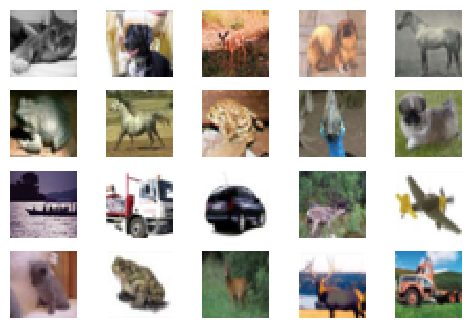

In [4]:
def plot_sample_images(ds):
  _, axes = plt.subplots(nrows=4, ncols=5, figsize=(6, 4))
  for i in range(4):
    for j in range(5):
        image = data_revert_norm_fn(ds[i*5+j])
        axes[i, j].imshow(image, cmap=plt.cm.gray_r, interpolation="nearest")
        axes[i, j].set_axis_off()


plot_sample_images(x_val)

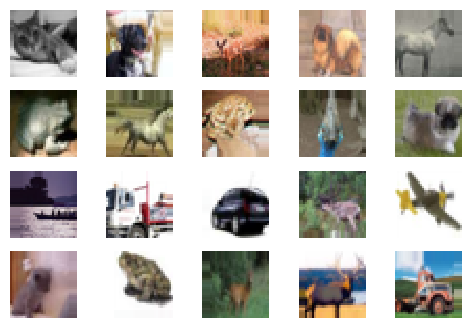

In [5]:
import jax.numpy as jnp

def augment(key, image):
    """Performs data augmentation."""
    # random crop
    image = jnp.pad(image, ((4, 4), (4, 4), (0, 0)), mode='edge')
    key, subkey = random.split(key)
    crop_x = random.randint(subkey, (), 0, 8)
    key, subkey = random.split(key)
    crop_y = random.randint(subkey, (), 0, 8)
    image = jax.lax.dynamic_slice_in_dim(image, crop_x, 32, 0)
    image = jax.lax.dynamic_slice_in_dim(image, crop_y, 32, 1)
    # image = image[crop_x:crop_x+32, crop_y:crop_y+32, :]
    # horizontal flip
    key, subkey = random.split(key)
    flip = random.bernoulli(subkey, 0.5)
    # image = jax.lax.cond(flip, image, lambda x: x, jnp.flip, image)
    image = jnp.where(flip, image, jnp.flip(image, axis=1))
    return key, image

key = jax.random.PRNGKey(0) 
key, img_random_crop = jax.lax.scan(augment, key, x_val[0:20])

plot_sample_images(img_random_crop)

### Train and eval not every batch

In [11]:
net = ResNet(num_classes=10, act_fn=nn.relu, block_class=ResNetBlock, num_blocks=(3,3,3), c_hidden=(16,32,64))
print(net.tabulate(jax.random.key(0), x[0:3],
                   compute_flops=False, compute_vjp_flops=False, console_kwargs={"width": 200}))


                                                                 ResNet Summary                                                                  
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ path                      ┃ module      ┃ inputs                       ┃ outputs             ┃ params                     ┃ batch_stats       ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│                           │ ResNet      │ float32[3,32,32,3]           │ float32[3,10]       │                            │                   │
├───────────────────────────┼─────────────┼──────────────────────────────┼─────────────────────┼────────────────────────────┼───────────────────┤
│ Conv_0                    │ Conv        │ float32[3,32,32,3]           │ float32[3,32,32,16] │ kernel: float32[3,3,3,16] 

In [12]:
def _predict(params, bn_params, inputs, train):
  # Predict logits from inputs and parameters
  all_params = {"params": params, "batch_stats": bn_params}

  def train_fn(inputs):
    logits, net_state = net.apply(
        all_params, inputs, train=True, mutable=["batch_stats"]
    )
    return logits, net_state

  def eval_fn(inputs):
    logits = net.apply(all_params, inputs, train=False, mutable=False)
    net_state = {"batch_stats": bn_params}
    return logits, net_state

  logits, net_state = jax.lax.cond(
      train, lambda x: train_fn(x), lambda x: eval_fn(x), inputs
  )
  return logits, net_state['batch_stats']


def l2_loss(x, alpha):
    return alpha * (x ** 2).sum()

def loss_fn(params, bn_params, inputs, targets, train:bool):
  logits, stats_params = _predict(params, bn_params, inputs, train)
#   print(logits.shape, targets.shape)
  loss = jnp.mean(
      optax.losses.softmax_cross_entropy_with_integer_labels(
          logits=logits, labels=targets)
  )
  loss = jax.lax.cond(train, lambda x: x+sum(l2_loss(w, alpha=1e-4)
               for w in jax.tree.leaves(params)), lambda x: x, loss)
  return loss, stats_params

  0%|          | 0/60 [00:00<?, ?it/s]

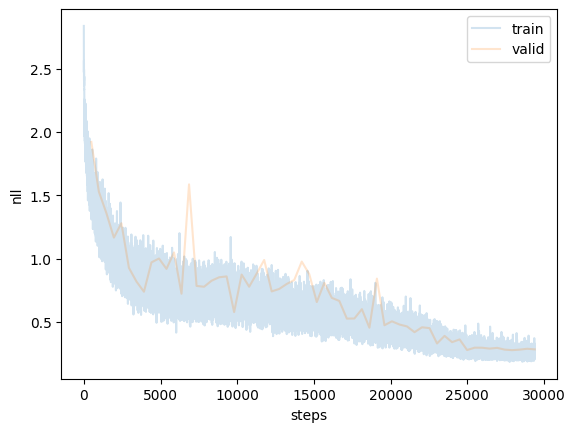

In [13]:
# imporved mini-batch approach with scan
config = dict(rng_seed=4,
              curve_params=dict(lr=1e-1, num_epochs=60))
BATCH_SIZE = 100

rng_key = random.PRNGKey(config['rng_seed'])
rng_key, init_key = random.split(rng_key)
params = net.init(init_key, x[0:2])
epochs = config['curve_params']['num_epochs']

# Train
lr = config['curve_params']['lr']
iter_per_epoch_train = len(x) // BATCH_SIZE
lr_schedule = optax.linear_onecycle_schedule(
    epochs * iter_per_epoch_train, lr
)
optimizer = optax.sgd(lr_schedule, momentum=0.9, nesterov=True)
opt_state = optimizer.init(params['params'])

best_loss = np.inf
best_params = params

def setup_metrics(batch_size, x, target):
    def acc_fn(params):
        x_ = x.reshape(-1, batch_size, 32, 32, 3)
        y_ = target.reshape(-1, batch_size)

        def pred(carry, x):
            logits, _ = _predict(
                params['params'], params['batch_stats'], x, train=False)
            return None, logits
        _, logits = jax.lax.scan(pred, None, x_)
        loss = jnp.mean(
            optax.losses.softmax_cross_entropy_with_integer_labels(
                logits=logits, labels=y_)
        )
        acc = jnp.mean(jnp.argmax(logits, axis=-1) == y_)
        return {'Acc':acc, 'Loss':loss}
    return acc_fn

valid_metrics_fn = setup_metrics(250, x_val, y_val)

def train_batch(carry, batch):
    x_, y_ = batch
    rng_key, params, opt_state, best_loss, best_params = carry
    rng_key, subkey = random.split(rng_key)

    net_params, stats_params = params['params'], params['batch_stats']

    (loss, stats_params), grads = jax.value_and_grad(loss_fn, argnums=0, has_aux=True)(net_params, stats_params, x_, y_, train=True)
    updates, opt_state = optimizer.update(grads, opt_state, net_params)
    net_params = optax.apply_updates(net_params, updates)

    return (rng_key, {'params': net_params, 'batch_stats': stats_params}, opt_state, best_loss, best_params), loss


@scan_tqdm(epochs)
def train(carry, _):
    rng_key = carry[0]
    rng_key, subkey = random.split(rng_key)
    shuffel = jax.random.permutation(subkey, jnp.arange(y.shape[0]))
    # data augmentation
    rng_key, x_ = jax.lax.scan(augment, rng_key, x)
    # x_ = x
    x_ = x_[shuffel].reshape(-1, BATCH_SIZE, 32, 32, 3)
    y_ = y[shuffel].reshape(-1, BATCH_SIZE)
    carry, loss_batch = jax.lax.scan(
        train_batch, carry, (x_, y_))
    
    # validate
    loss_epoch = jnp.mean(loss_batch)
    params, best_loss, best_params = carry[1], carry[3], carry[4]

    metrics = valid_metrics_fn(params)
    val_loss = metrics['Loss']
    best_params = jax.lax.cond(
        val_loss < best_loss, lambda x: params, lambda x: best_params, None)
    best_loss = jnp.minimum(best_loss, val_loss)

    return (rng_key, params, carry[2], best_loss, best_params), (loss_batch, val_loss, metrics['Acc'])


carry = (rng_key, params, opt_state, best_loss, best_params)

# for epoch in tqdm(range(epochs)):
#     rng_key = carry[0]
#     shuffel = jax.random.permutation(rng_key, jnp.arange(y.shape[0]))
#     x_ = x[shuffel].reshape(-1, batch_size, 28, 28, 1)
#     y_ = y[shuffel].reshape(-1, batch_size)
#     carry, (loss, valid_loss) = jax.lax.scan(train_batch, carry, (x_, y_))
#     losses.append(loss.mean())
#     valid_losses.append(valid_loss.mean())

carry, (losses, valid_losses, valid_acc) = jax.lax.scan(train, carry, jnp.arange(epochs))
rng_key, params, opt_state, best_loss, best_params = carry

n_steps_e = losses.shape[1]
plt.plot(np.array(losses).flatten(), alpha=0.2, label="train")
plt.plot(np.arange(n_steps_e, n_steps_e*epochs+1, n_steps_e), np.array(
    valid_losses).flatten(), alpha=0.2, label="valid")
plt.ylabel("nll")
plt.xlabel("steps")
plt.legend()
plt.show()
# wandb.finish()

(0.0, 35000.0)

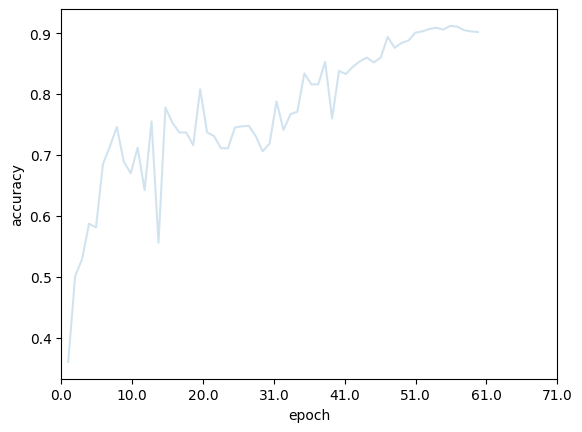

In [14]:
plt.plot(np.arange(n_steps_e, n_steps_e*epochs+1, n_steps_e), np.array(
    valid_acc).flatten(), alpha=0.2, label="valid")
#set xticks to epoch
plt.xticks(plt.gca().get_xticks(), np.round(plt.gca().get_xticks()/n_steps_e,0))
plt.ylabel("accuracy")
plt.xlabel("epoch")
plt.xlim(0)

In [15]:
logits, _ = _predict(params['params'], params['batch_stats'], x_val, train=False)
probs = jax.nn.softmax(logits, axis=-1)
selected_probs = probs[np.arange(probs.shape[0]), y_val]
nll = -jnp.mean(jnp.log(selected_probs))
nll

Array(0.2820641, dtype=float32)

In [16]:
print("nll from optx: ", jnp.mean(
      optax.losses.softmax_cross_entropy_with_integer_labels(
          logits=logits, labels=y_val)))

nll from optx:  0.2820641


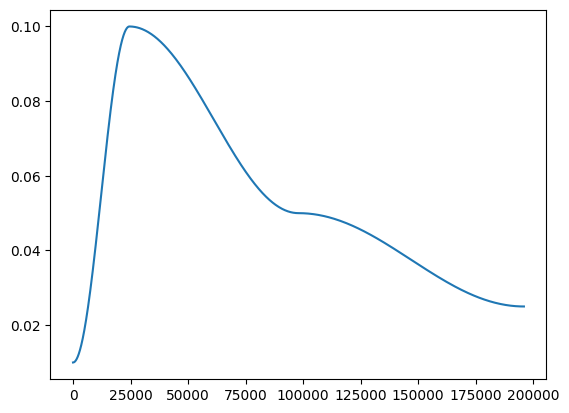

In [26]:
# different lr schedulers
iter_per_epoch_train = 49000 // 100
sched = schedules.piecewise_interpolate_schedule(
    "cosine", 0.01, {iter_per_epoch_train*50: 10., iter_per_epoch_train*200: 0.5, iter_per_epoch_train*400: 0.5})
lr_time = jax.vmap(sched)(jnp.arange(400*iter_per_epoch_train))
plt.plot(lr_time)

#### ACC

In [31]:
rng_key, params, opt_state, best_loss, best_params = carry

acc_fn = setup_metrics(250, x_val, y_val)
acc_fn(best_params)

{'Acc': Array(0.93000007, dtype=float32),
 'Loss': Array(0.24567826, dtype=float32)}

In [32]:
acc_fn = setup_metrics(500, x_test, y_test)
print("test acc:", acc_fn(best_params))

test acc: {'Acc': Array(0.9145, dtype=float32), 'Loss': Array(0.27961108, dtype=float32)}


#### save params

In [34]:
jnp.save("tmp_files/cifar10_best_params.npy", best_params)

### Train Curve Model

In [7]:
from src.subspace_curve import CategorySubspaceBatchNorm
# define the subspace model to optimize the path
config = dict(rng_seed=4,
              curve_params=dict(k=10, lr=0.01, num_epochs=31))
BATCH_SIZE = 100
EVAL_EVERY_N_BATCH = 10

resnet20 = ResNet(num_blocks=(3, 3, 3), c_hidden=(16*4, 32*4, 64*4),
             num_classes=10, act_fn=nn.relu, block_class=ResNetBlock)
s_model = CategorySubspaceBatchNorm(resnet20, config['curve_params']['k'], weight_decay=0.0)
rng_key = random.PRNGKey(0)
rng_key, init_key = random.split(rng_key)
params = s_model.init_params(init_key, x[0:10])
params['params']  # shape (k+1, 3, 16)

{'BatchNorm_0': {'bias': Array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0.

In [7]:
print(resnet20.tabulate(jax.random.key(0), x[0:3],
                   compute_flops=False, compute_vjp_flops=False, console_kwargs={"width": 200}))


                                                                   ResNet Summary                                                                    
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┓
┃ path                      ┃ module      ┃ inputs                       ┃ outputs              ┃ params                       ┃ batch_stats        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━┩
│                           │ ResNet      │ float32[3,32,32,3]           │ float32[3,10]        │                              │                    │
├───────────────────────────┼─────────────┼──────────────────────────────┼──────────────────────┼──────────────────────────────┼────────────────────┤
│ Conv_0                    │ Conv        │ float32[3,32,32,3]           │ float32[3,32,32,64]  │ k

In [ ]:
# imporved mini-batch approach with scan

# Train
epochs = config['curve_params']['num_epochs']
# lr = config['curve_params']['lr']
# iter_per_epoch_train = len(x) // BATCH_SIZE
# lr_schedule = optax.linear_onecycle_schedule(
#     epochs * iter_per_epoch_train, lr, pct_start=0.1, div_factor=10.0, final_div_factor=100.0
# )
# optimizer = optax.sgd(lr_schedule, momentum=0.9, nesterov=True)

optimizer = optax.adamw(config['curve_params']['lr'], weight_decay=1e-5, b1=0.7, b2=0.85)
opt_state = optimizer.init({'params': params['params']})

losses = []
valid_losses = []
best_loss = np.inf
best_params = params
epochs = config['curve_params']['num_epochs']

def setup_metrics(batch_size, x, target, n_samples, use_linspace=False, average=True):
            if use_linspace:
                get_t = lambda key: jnp.linspace(0, 1., n_samples)
            else:
                get_t = lambda key: random.uniform(key, (n_samples,), minval=0., maxval=1.)

            def acc_fn(rng_key, params):
                x_ = x.reshape(-1, batch_size, 32, 32, 3)
                y_ = target.reshape(-1, batch_size)

                def pred(key, data):
                    x_batch, y_batch = data

                    def eval(t):
                        logits, _ = s_model.eval(
                            params['params'], params['batch_stats'], t, x_batch)  # params, batch_stats, t, x
                        loss = jnp.mean(optax.losses.softmax_cross_entropy_with_integer_labels(
                            logits=logits, labels=y_batch))
                        acc = jnp.mean(jnp.argmax(logits, axis=-1) == y_batch)
                        return loss, acc  # mean over batch
                    key, subkey = random.split(key)

                    # draw 10 samples to approximate curve performance
                    t = get_t(subkey)
                    loss, acc = jax.vmap(eval)(t)

                    if average:
                        return key, (jnp.mean(loss), jnp.mean(acc))  # mean over samples
                    else:
                        return key, (loss, acc)  # no mean over samples

                # shape (n_data, draws, output_dim)
                rng_key, (loss, acc) = jax.lax.scan(pred, rng_key, (x_, y_))
                loss = jnp.mean(loss, axis=0)
                acc = jnp.mean(acc, axis=0)
                return loss, acc  # mean over epochs
            return acc_fn
valid_metrics_fn = setup_metrics(250, x_val, y_val, n_samples=10)


def train_batch(carry, batch):
    x_, y_, batch_idx = batch
    rng_key, params, opt_state, best_loss, best_params = carry
    rng_key, subkey = random.split(rng_key)
    loss, params, opt_state, _ = s_model.train_step(
        subkey, params, x_, y_, opt_state, optimizer)
    # validate
    rng_key, valid_key = random.split(rng_key)
    # val_loss = s_model.compute_loss(
    #     subkey, params, x_val, y_val, n_samples=10)
    # best_params = jax.lax.cond(
    #     val_loss < best_loss, lambda x: params, lambda x: best_params, None)
    # best_loss = jnp.minimum(best_loss, val_loss)

    # acc, val_loss = valid_metrics_fn(valid_key, params)
    val_loss, acc = jax.lax.cond((batch_idx % 10) == 0, lambda x: valid_metrics_fn(
        valid_key, params), lambda x: (-jnp.inf, jnp.inf), None)
    best_params = jax.lax.cond(
        val_loss < best_loss, lambda x: params, lambda x: best_params, None)
    best_loss = jnp.minimum(best_loss, val_loss)

    return (rng_key, params, opt_state, best_loss, best_params), (loss, val_loss, acc)


@scan_tqdm(epochs)
def train(carry, epoch):
    rng_key = carry[0]
    rng_key, subkey = random.split(rng_key)
    shuffel = jax.random.permutation(subkey, jnp.arange(y.shape[0]))
    # data augmentation
    rng_key, x_ = jax.lax.scan(augment, rng_key, x)
    # x_ = x
    x_ = x_[shuffel].reshape(-1, BATCH_SIZE, 32, 32, 3)
    y_ = y[shuffel].reshape(-1, BATCH_SIZE)
    carry, (loss, val_loss, val_acc) = jax.lax.scan(
        train_batch, carry, (x_, y_, jnp.arange(x_.shape[0])))

    return carry, (loss, val_loss, val_acc)


carry = (rng_key, params, opt_state, best_loss, best_params)

# for epoch in tqdm(range(epochs)):
#     rng_key = carry[0]
#     shuffel = jax.random.permutation(rng_key, jnp.arange(y.shape[0]))
#     x_ = x[shuffel].reshape(-1, batch_size, 28, 28, 1)
#     y_ = y[shuffel].reshape(-1, batch_size)
#     carry, (loss, valid_loss) = jax.lax.scan(train_batch, carry, (x_, y_))
#     losses.append(loss.mean())
#     valid_losses.append(valid_loss.mean())

carry, (losses, valid_losses, acc) = jax.lax.scan(train, carry, jnp.arange(epochs))
rng_key, params, opt_state, best_loss, best_params = carry

valid_losses = valid_losses[:, ::EVAL_EVERY_N_BATCH].repeat(
    EVAL_EVERY_N_BATCH, axis=1)[:,:valid_losses.shape[1]]
valid_acc = acc[:, ::EVAL_EVERY_N_BATCH].repeat(
    EVAL_EVERY_N_BATCH, axis=1)[:, :acc.shape[1]]
plt.plot(np.array(losses).flatten(), alpha=0.2)
plt.plot(np.arange(0, epochs*losses.shape[1], losses.shape[1]),
         np.array(losses).mean(-1), c=plt.get_cmap('tab10')(0))
plt.plot(np.array(valid_losses).flatten(), alpha=0.2)
plt.plot(np.arange(0, epochs*losses.shape[1], losses.shape[1]),
         np.array(valid_losses).mean(-1), c=plt.get_cmap('tab10')(1))
# set x ticks to epochs
plt.xticks(np.arange(
    0, epochs*losses.shape[1], losses.shape[1]*5), np.arange(0, epochs, 5))
plt.ylabel("nll")
plt.xlabel("epochs")
plt.ylim(0, 10)

  0%|          | 0/31 [00:00<?, ?it/s]

(0.0, 10.0)

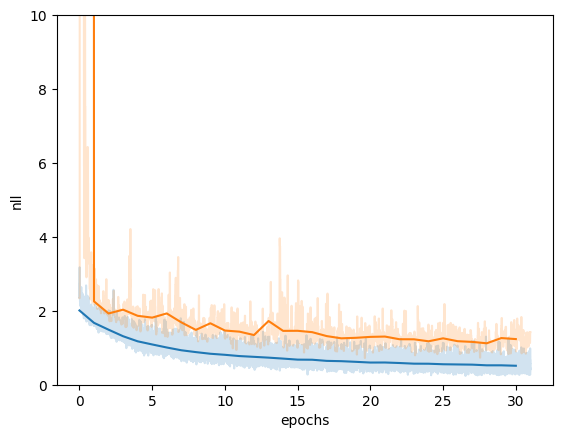

In [52]:

valid_losses = valid_losses[:, ::EVAL_EVERY_N_BATCH].repeat(
    EVAL_EVERY_N_BATCH, axis=1)[:,:valid_losses.shape[1]]

plt.plot(np.array(losses).flatten(), alpha=0.2)
plt.plot(np.arange(0, epochs*losses.shape[1], losses.shape[1]),
         np.array(losses).mean(-1), c=plt.get_cmap('tab10')(0))
plt.plot(np.array(valid_losses).flatten(), alpha=0.2)
plt.plot(np.arange(0, epochs*losses.shape[1], losses.shape[1]),
         np.array(valid_losses).mean(-1), c=plt.get_cmap('tab10')(1))
# set x ticks to epochs
plt.xticks(np.arange(
    0, epochs*losses.shape[1], losses.shape[1]*5), np.arange(0, epochs, 5))
plt.ylabel("nll")
plt.xlabel("epochs")
plt.ylim(0, 10)

In [38]:
valid_losses[:, ::10].repeat(10, axis=1)[0]

Array([2.3442001e+00, 2.3442001e+00, 2.3442001e+00, 2.3442001e+00,
       2.3442001e+00, 2.3442001e+00, 2.3442001e+00, 2.3442001e+00,
       2.3442001e+00, 2.3442001e+00, 7.5353735e+03, 7.5353735e+03,
       7.5353735e+03, 7.5353735e+03, 7.5353735e+03, 7.5353735e+03,
       7.5353735e+03, 7.5353735e+03, 7.5353735e+03, 7.5353735e+03,
       3.9812621e+04, 3.9812621e+04, 3.9812621e+04, 3.9812621e+04,
       3.9812621e+04, 3.9812621e+04, 3.9812621e+04, 3.9812621e+04,
       3.9812621e+04, 3.9812621e+04, 9.3717363e+03, 9.3717363e+03,
       9.3717363e+03, 9.3717363e+03, 9.3717363e+03, 9.3717363e+03,
       9.3717363e+03, 9.3717363e+03, 9.3717363e+03, 9.3717363e+03,
       2.8280828e+03, 2.8280828e+03, 2.8280828e+03, 2.8280828e+03,
       2.8280828e+03, 2.8280828e+03, 2.8280828e+03, 2.8280828e+03,
       2.8280828e+03, 2.8280828e+03, 3.5536996e+04, 3.5536996e+04,
       3.5536996e+04, 3.5536996e+04, 3.5536996e+04, 3.5536996e+04,
       3.5536996e+04, 3.5536996e+04, 3.5536996e+04, 3.5536996e

In [41]:
valid_losses_new = jnp.where(jnp.isinf(valid_losses), valid_losses[:, ::10].repeat(10, axis=1), valid_losses)
# valid_losses_new = jnp.where(
#     jnp.isinf(valid_losses_new), jnp.roll(valid_losses_new, 1), valid_losses_new)
valid_losses_new[0]

Array([2.3442001e+00, 2.3442001e+00, 2.3442001e+00, 2.3442001e+00,
       2.3442001e+00, 2.3442001e+00, 2.3442001e+00, 2.3442001e+00,
       2.3442001e+00, 2.3442001e+00, 7.5353735e+03, 7.5353735e+03,
       7.5353735e+03, 7.5353735e+03, 7.5353735e+03, 7.5353735e+03,
       7.5353735e+03, 7.5353735e+03, 7.5353735e+03, 7.5353735e+03,
       3.9812621e+04, 3.9812621e+04, 3.9812621e+04, 3.9812621e+04,
       3.9812621e+04, 3.9812621e+04, 3.9812621e+04, 3.9812621e+04,
       3.9812621e+04, 3.9812621e+04, 9.3717363e+03, 9.3717363e+03,
       9.3717363e+03, 9.3717363e+03, 9.3717363e+03, 9.3717363e+03,
       9.3717363e+03, 9.3717363e+03, 9.3717363e+03, 9.3717363e+03,
       2.8280828e+03, 2.8280828e+03, 2.8280828e+03, 2.8280828e+03,
       2.8280828e+03, 2.8280828e+03, 2.8280828e+03, 2.8280828e+03,
       2.8280828e+03, 2.8280828e+03, 3.5536996e+04, 3.5536996e+04,
       3.5536996e+04, 3.5536996e+04, 3.5536996e+04, 3.5536996e+04,
       3.5536996e+04, 3.5536996e+04, 3.5536996e+04, 3.5536996e

(0.0, 4.0)

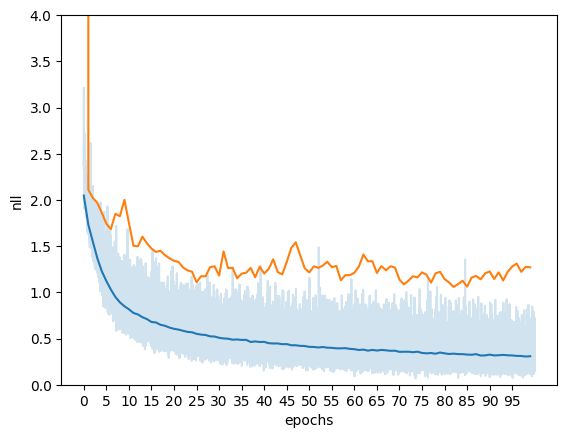

In [15]:
plt.plot(np.array(losses).flatten(), alpha=0.2)
plt.plot(np.arange(0, epochs*losses.shape[1], losses.shape[1]),
         np.array(losses).mean(-1), c=plt.get_cmap('tab10')(0))
plt.plot(np.arange(0, epochs*losses.shape[1], losses.shape[1]),
         valid_losses[jnp.isfinite(valid_losses)].reshape(epochs, -1).mean(-1), c=plt.get_cmap('tab10')(1))
# set x ticks to epochs
plt.xticks(np.arange(
    0, epochs*losses.shape[1], losses.shape[1]*5), np.arange(0, epochs, 5))
plt.ylabel("nll")
plt.xlabel("epochs")
plt.ylim(0, 4)

Text(0.5, 0, 'epochs')

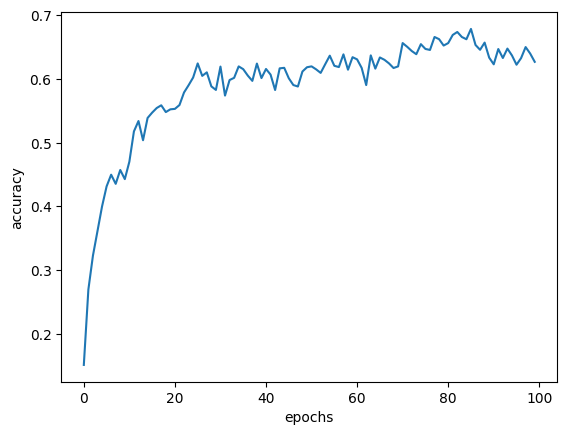

In [16]:
plt.plot(acc[jnp.isfinite(acc)].reshape(epochs, -1).mean(-1))
plt.ylabel("accuracy")
plt.xlabel("epochs")

Text(0.5, 0, 'epochs')

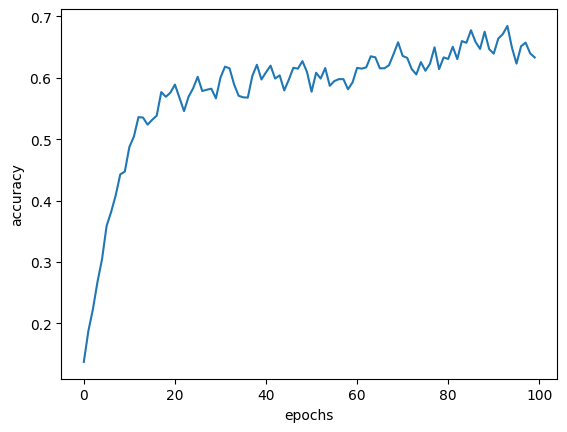

In [14]:
plt.plot(acc[jnp.isfinite(acc)].reshape(epochs, -1).mean(-1))
plt.ylabel("accuracy")
plt.xlabel("epochs")

(0.0, 10.0)

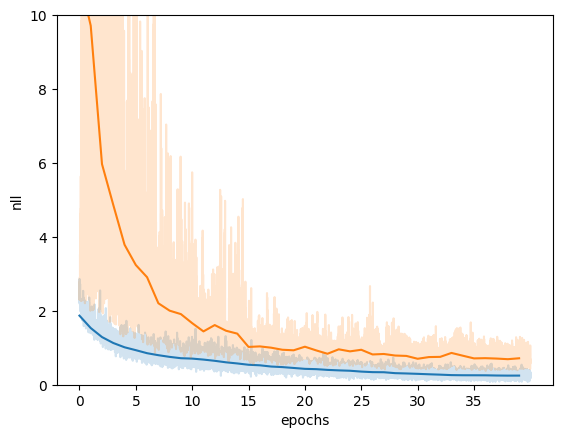

In [14]:
plt.plot(np.array(losses).flatten(), alpha=0.2)
plt.plot(np.arange(0, epochs*losses.shape[1], losses.shape[1]),
         np.array(losses).mean(-1), c=plt.get_cmap('tab10')(0))
plt.plot(np.array(valid_losses).flatten(), alpha=0.2)
plt.plot(np.arange(0, epochs*losses.shape[1], losses.shape[1]),
         np.array(valid_losses).mean(-1), c=plt.get_cmap('tab10')(1))
# set x ticks to epochs
plt.xticks(np.arange(
    0, epochs*losses.shape[1], losses.shape[1]*5), np.arange(0, epochs, 5))
plt.ylabel("nll")
plt.xlabel("epochs")
plt.ylim(0, 10)

In [120]:
def setup_metrics(batch_size, x, target, n_samples):
    def acc_fn(rng_key, params):
        x_ = x.reshape(-1, batch_size, 32, 32, 3)
        y_ = target.reshape(-1, batch_size)

        def pred(key, data):
            x_batch, y_batch = data
            def eval(t):
                logits, _ = s_model.eval(
                    params['params'], params['batch_stats'], t, x_batch)  # params, batch_stats, t, x
                loss = jnp.mean(optax.losses.softmax_cross_entropy_with_integer_labels(
                    logits=logits, labels=y_batch))
                acc = jnp.mean(jnp.argmax(logits, axis=-1) == y_batch) 
                return loss, acc  # mean over batch
            key, subkey = random.split(key)

            # draw 10 samples to approximate curve performance
            t = random.uniform(subkey, (n_samples,), minval=0., maxval=1.)
            loss, acc = jax.vmap(eval)(t)

            return key, (jnp.mean(loss), jnp.mean(acc)) # mean over samples

        # shape (n_data, draws, output_dim)
        rng_key, (loss, acc) = jax.lax.scan(pred, rng_key, (x_, y_))
        loss = jnp.mean(loss)
        acc = jnp.mean(acc)
        return acc, loss # mean over epochs
    return acc_fn

In [17]:
acc_fn = setup_metrics(250, x_val, y_val, n_samples=10)
acc_fn(rng_key, params)

(Array(0.6140001, dtype=float32), Array(1.2980788, dtype=float32))

In [128]:
jnp.minimum(jnp.inf, 1)

Array(1., dtype=float32, weak_type=True)

In [18]:
acc_fn = setup_metrics(250, x_val, y_val, n_samples=10)
acc_fn(rng_key, best_params)

(Array(0.6887001, dtype=float32), Array(0.91714996, dtype=float32))

In [19]:
acc_fn = setup_metrics(250, x, y, n_samples=10)
acc_fn(rng_key, best_params)

(Array(0.72237355, dtype=float32), Array(0.83370936, dtype=float32))

In [126]:
os.makedirs("temp", exist_ok=True)
jnp.savez("temp/params_train_acc89_nll35.npz", params)

  0%|          | 0/100 [00:00<?, ?it/s]

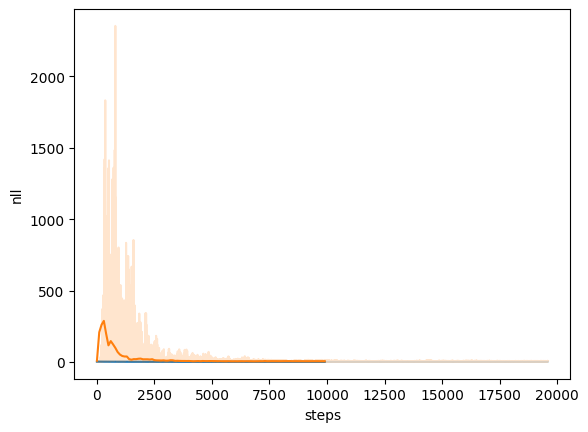

In [ ]:
# define the subspace model to optimize the path
config = dict(rng_seed=4,
              curve_params=dict(k=10, lr=1e-1, num_epochs=100))
BATCH_SIZE = 250

s_model = CategorySubspaceBatchNorm(net, config['curve_params']['k'])
rng_key = random.PRNGKey(0)
rng_key, init_key = random.split(rng_key)
params = s_model.init_params(init_key, x[0:10])
params['params']  # shape (k+1, 3, 16)


# imporved mini-batch approach with scan

# Train
lr = config['curve_params']['lr']
iter_per_epoch_train = len(x) // BATCH_SIZE
lr_schedule = optax.linear_onecycle_schedule(
    epochs * iter_per_epoch_train, lr
)
optimizer = optax.sgd(lr_schedule, momentum=0.9, nesterov=True)
opt_state = optimizer.init({'params': params['params']})

losses = []
valid_losses = []
best_loss = np.inf
best_params = params
epochs = config['curve_params']['num_epochs']


def setup_metrics(batch_size, x, target):
    @jit
    def acc_fn(rng_key, params):
        x_ = x.reshape(-1, batch_size, 32, 32, 3)
        y_ = target.reshape(-1, batch_size)

        def pred(key, x):
            def eval(t):
                logits, _ = s_model.eval(
                    params['params'], params['batch_stats'], t, x)  # params, batch_stats, t, x
                return logits
            key, subkey = random.split(key)
            # draw 10 samples to approximate curve performance
            t = random.uniform(subkey, (10,), minval=0., maxval=1.)
            map_logits = jax.vmap(eval)(t)
            return key, map_logits

        # shape (n_data, draws, output_dim)
        rng_key, logits = jax.lax.scan(pred, rng_key, x_)

        def metrics(logits):
            loss = jnp.mean(optax.losses.softmax_cross_entropy_with_integer_labels(
                logits=logits, labels=y_))
            acc = jnp.mean(jnp.argmax(logits, axis=-1) == y_)
            return acc, loss
        acc, loss = jax.vmap(metrics, in_axes=1)(logits)  # vmap over samples
        loss = jnp.mean(loss)
        acc = jnp.mean(acc)
        return acc, loss
    return acc_fn


valid_metrics_fn = setup_metrics(250, x_val, y_val)


def train_batch(carry, batch):
    x_, y_ = batch
    rng_key, params, opt_state, best_loss, best_params = carry
    rng_key, subkey = random.split(rng_key)

    loss, params, opt_state, _ = s_model.train_step(
        subkey, params, x_, y_, opt_state, optimizer)

    # validate
    rng_key, valid_key = random.split(rng_key)
    acc, val_loss = valid_metrics_fn(valid_key, params)
    best_params = jax.lax.cond(
        val_loss < best_loss, lambda x: params, lambda x: best_params, None)
    best_loss = jnp.minimum(best_loss, val_loss)

    return (rng_key, params, opt_state, best_loss, best_params), (loss, val_loss, acc)


@scan_tqdm(epochs)
def train(carry, _):
    rng_key = carry[0]
    rng_key, subkey = random.split(rng_key)
    shuffel = jax.random.permutation(subkey, jnp.arange(y.shape[0]))
    # data augmentation
    rng_key, x_ = jax.lax.scan(augment, rng_key, x)
    # x_ = x
    x_ = x_[shuffel].reshape(-1, BATCH_SIZE, 32, 32, 3)
    y_ = y[shuffel].reshape(-1, BATCH_SIZE)
    carry, (loss, val_loss, val_acc) = jax.lax.scan(
        train_batch, carry, (x_, y_))

    return carry, (loss, val_loss, val_acc)


carry = (rng_key, params, opt_state, best_loss, best_params)

# for epoch in tqdm(range(epochs)):
#     rng_key = carry[0]
#     shuffel = jax.random.permutation(rng_key, jnp.arange(y.shape[0]))
#     x_ = x[shuffel].reshape(-1, batch_size, 28, 28, 1)
#     y_ = y[shuffel].reshape(-1, batch_size)
#     carry, (loss, valid_loss) = jax.lax.scan(train_batch, carry, (x_, y_))
#     losses.append(loss.mean())
#     valid_losses.append(valid_loss.mean())

carry, (losses, valid_losses, acc) = jax.lax.scan(
    train, carry, jnp.arange(epochs))
rng_key, params, opt_state, best_loss, best_params = carry

plt.plot(np.array(losses).flatten(), alpha=0.2)
plt.plot(np.arange(0, epochs*100, 100),
         np.array(losses).mean(-1), c=plt.get_cmap('tab10')(0))
plt.plot(np.array(valid_losses).flatten(), alpha=0.2)
plt.plot(np.arange(0, epochs*100, 100),
         np.array(valid_losses).mean(-1), c=plt.get_cmap('tab10')(1))
plt.ylabel("nll")
plt.xlabel("steps")
plt.show()

In [113]:
losses.shape

(100, 196)

(0.0, 10.0)

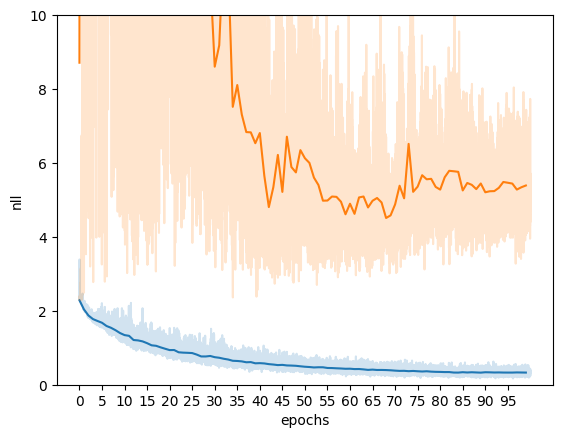

In [120]:
plt.plot(np.array(losses).flatten(), alpha=0.2)
plt.plot(np.arange(0, epochs*losses.shape[1], losses.shape[1]),
         np.array(losses).mean(-1), c=plt.get_cmap('tab10')(0))
plt.plot(np.array(valid_losses).flatten(), alpha=0.2)
plt.plot(np.arange(0, epochs*losses.shape[1], losses.shape[1]),
         np.array(valid_losses).mean(-1), c=plt.get_cmap('tab10')(1))
# set x ticks to epochs
plt.xticks(np.arange(0, epochs*losses.shape[1], losses.shape[1]*5), np.arange(0,epochs,5))
plt.ylabel("nll")
plt.xlabel("epochs")
plt.ylim(0, 10)

Text(0.5, 0, 'epochs')

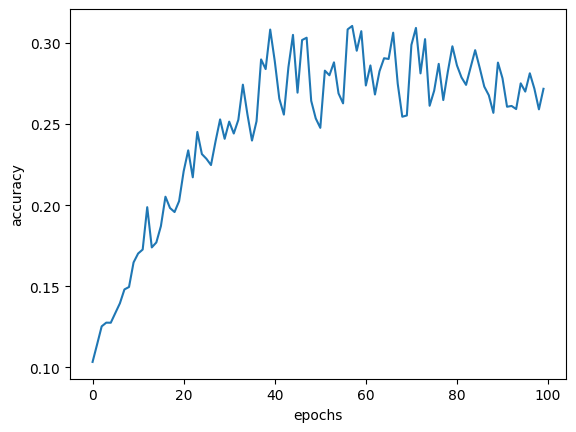

In [110]:
plt.plot(acc.mean(-1))
plt.ylabel("accuracy")
plt.xlabel("epochs")

### Train point to curve

In [71]:
aa = jax.random.normal(jax.random.PRNGKey(0), (3, 4))

def sum_pairwise_distances(A):
    n = A.shape[0]
    def body_fun(i, acc):
        diffs = A - A[i]
        dists = jnp.linalg.norm(diffs, axis=-1)      # shape: (n)
        dists = jnp.where(jnp.arange(0,n)>i, dists, 0.) # use only i+1: elements
        return acc + jnp.sum(dists)
    return jax.lax.fori_loop(0, n - 1, body_fun, 0.0)
sum_pairwise_distances(aa)

Array(8.517923, dtype=float32)

In [72]:


def sum_pairwise_distances_fast_huge_memory(A):
    diff = A[:, jnp.newaxis, :] - A[jnp.newaxis, :, :]  # shape (n, n, d)
    dists = jnp.linalg.norm(diff, axis=-1)             # shape (n, n)
    i_upper = jnp.triu_indices(len(A), k=1)            # upper triangle indices
    return jnp.sum(dists[i_upper])

sum_pairwise_distances_fast_huge_memory(aa)

Array(8.517923, dtype=float32)

Define force and minimize to simulate repulsive force

summation same as using upper tirangle of difference matrix shape (k,k,d)

$f = \frac{\gamma}{\sum_{i=0}^{K-2}\sum_{j=i+1}^{K-1} ||\theta_i - \theta_{i+1}||^2} (1)$

$f = \sum_{i=0}^{K-2}\sum_{j=i+1}^{K-1}\frac{\gamma}{ ||\theta_i - \theta_{j}||^2} (2)$  (correct)

$f = \sum_{i=0}^{K-2}\sum_{j=i+1}^{K-1}\frac{\gamma}{ ||\theta_i - \theta_{j}||^2+1e-3} (3)$  (stable)

In [6]:
from src.subspace_curve import CategorySubspaceBatchNorm, PermutationSpec

class RepulsiveCategorySubspaceBatchNorm(CategorySubspaceBatchNorm):
    def __init__(self, model, k, weight_decay, perm_spec: PermutationSpec=False, natural_parameterization=False, gravity=0.0):
        """
        Initializes the RepulsiveCategorySubspaceBatchNorm class.

        Parameters:
        - model: The model to be used.
        - k: The number of control points.
        - out_scale: The output scale.
        - optimize_distparams: Whether to optimize the distribution parameters.
        - gravity: The gravity parameter.
        """
        super().__init__(model, k, weight_decay, perm_spec, natural_parameterization)
        self.gravity = gravity

    def repulsive_force(self, params):
        """
        Computes the repulsive force between the parameters.

        Parameters:
        - params: The parameters of the model.

        Returns:
        - The repulsive force.
        """
        cp_w = pytree_to_matrix(params['params'], self.k)
        def sum_pairwise_distances(A):
            n = A.shape[0]
            def body_fun(i, acc):
                diffs = A - A[i]
                dists = jnp.sum(diffs**2, axis=-1)      # shape: (n)    
                # dists = jnp.linalg.norm(diffs, axis=-1)      # shape: (n)
                dists = self.gravity/(dists+1e-3)
                dists = jnp.where(jnp.arange(0,n)>i, dists, 0.) # masking: use only i+1: elements
                return acc + jnp.sum(dists)
            return jax.lax.fori_loop(0, n - 1, body_fun, 0.0)
        force = sum_pairwise_distances(cp_w)
        return force

    
    def nll(self, params, param_stats, t, x, y):
        """
        Computes the negative log-likelihood loss of the model.

        Parameters:
        - params: The parameters of the model.
        - t: The time parameter.
        - x: The input data.
        - y: The target output.

        Returns:
        - The negative log-likelihood loss.
        """
        nll, batch_stats = super().nll(params, param_stats, t, x, y)
        rep_force = self.repulsive_force(params)
        # jax.debug.print("nll: {}",nll)
        # jax.debug.print("forece: {}",rep_force)
        return nll + rep_force, batch_stats
    

In [15]:
params = jnp.load("tmp_files/34n0kfju_params.npy", allow_pickle=True).item()
curve_params = [deepcopy(params['params']) for _ in range(k+1)]

# add noise to the parameters
param, struct = jax.tree.flatten(curve_params)
rng = random.PRNGKey(0)
keys = random.split(rng, len(param))
def apply_noise(p, key, jitter):
    return p+jitter*jax.random.normal(key, p.shape)
noise_params = [apply_noise(p, key, jitter=1e-5) for p, key in zip(param, keys)]
curve_params = jax.tree.unflatten(struct, noise_params)


curve_params = jax.tree.map(lambda *x: jnp.stack(x), *curve_params)  
curve_params

{'BatchNorm_0': {'bias': Array([[-0.00221095,  0.2576088 ,  0.23950404,  0.21376304, -0.01236326,
          -0.42919883,  0.03109739,  0.43770325,  0.82726973,  0.24546562,
           0.2998245 , -0.23906128,  0.46675718,  0.20495938,  0.24621268,
           0.22064795],
         [-0.00219582,  0.25760338,  0.23947948,  0.21376213, -0.01236706,
          -0.42919663,  0.0311042 ,  0.43768865,  0.8272739 ,  0.24547268,
           0.29983205, -0.2390218 ,  0.46673203,  0.20495732,  0.24620377,
           0.22066565],
         [-0.00219479,  0.25761208,  0.23948894,  0.21374986, -0.0123708 ,
          -0.4292017 ,  0.03110591,  0.4376921 ,  0.8272503 ,  0.24545106,
           0.29982445, -0.23902702,  0.46674928,  0.20496187,  0.24618539,
           0.22065334],
         [-0.00219421,  0.2576198 ,  0.23947564,  0.21374264, -0.01236331,
          -0.42921788,  0.03111047,  0.43767685,  0.8272649 ,  0.24547696,
           0.29984447, -0.23903964,  0.46675056,  0.20494653,  0.24621145,
     

In [18]:

print(curve_params['Conv_0']['kernel'][0][0][0][0])
curve_params['Conv_0']['kernel'][1][0][0][0]

[ 3.19859158e-04  1.25736594e-02  1.71065092e-01 -2.52585113e-01
 -6.53280541e-02  1.10097155e-01  2.74454914e-02 -3.73544484e-01
 -1.35074044e-02 -3.48588289e-03  6.82726577e-02  1.12411484e-01
  4.53288466e-01 -1.17933780e-01  1.11021936e-01  5.93753792e-02]


Array([ 3.13421624e-04,  1.25633013e-02,  1.71074957e-01, -2.52564251e-01,
       -6.53480813e-02,  1.10091284e-01,  2.74718832e-02, -3.73521179e-01,
       -1.34999668e-02, -3.49386781e-03,  6.82562515e-02,  1.12419270e-01,
        4.53263372e-01, -1.17928870e-01,  1.11003235e-01,  5.93820363e-02],      dtype=float32)

In [16]:
curve_params['Conv_0']['kernel']

Array([[[[[ 3.19859158e-04,  1.25736594e-02,  1.71065092e-01, ...,
           -1.17933780e-01,  1.11021936e-01,  5.93753792e-02],
          [ 3.31651303e-04,  1.06411101e-03,  7.57575259e-02, ...,
            2.70249713e-02,  7.51682594e-02, -7.01349303e-02],
          [ 5.39671979e-04, -4.81301593e-03, -1.16813324e-01, ...,
            6.70230910e-02,  8.11931416e-02,  1.78833604e-01]],

         [[ 3.90522211e-04, -2.52205748e-02,  3.99556428e-01, ...,
           -2.48945445e-01,  2.21483544e-01,  1.83928162e-01],
          [ 3.02837958e-04, -1.39344379e-01, -4.69680950e-02, ...,
            1.12528160e-01,  1.91616938e-01, -2.70805895e-01],
          [ 1.92309002e-04, -1.26182377e-01, -2.28163674e-01, ...,
            3.04544806e-01,  1.07900850e-01,  2.56450802e-01]],

         [[-5.40192006e-04, -2.08060488e-01,  3.96070570e-01, ...,
            1.90350115e-02,  3.29200141e-02,  1.42511204e-01],
          [-6.16750563e-04, -3.10316265e-01, -1.47762492e-01, ...,
            4.37627

In [36]:
struct

PyTreeDef([{'BatchNorm_0': {'bias': *, 'scale': *}, 'Conv_0': {'kernel': *}, 'Dense_0': {'bias': *, 'kernel': *}, 'ResNetBlock_0': {'BatchNorm_0': {'bias': *, 'scale': *}, 'BatchNorm_1': {'bias': *, 'scale': *}, 'Conv_0': {'kernel': *}, 'Conv_1': {'kernel': *}}, 'ResNetBlock_1': {'BatchNorm_0': {'bias': *, 'scale': *}, 'BatchNorm_1': {'bias': *, 'scale': *}, 'Conv_0': {'kernel': *}, 'Conv_1': {'kernel': *}}, 'ResNetBlock_2': {'BatchNorm_0': {'bias': *, 'scale': *}, 'BatchNorm_1': {'bias': *, 'scale': *}, 'Conv_0': {'kernel': *}, 'Conv_1': {'kernel': *}}, 'ResNetBlock_3': {'BatchNorm_0': {'bias': *, 'scale': *}, 'BatchNorm_1': {'bias': *, 'scale': *}, 'Conv_0': {'kernel': *}, 'Conv_1': {'kernel': *}, 'Conv_2': {'bias': *, 'kernel': *}}, 'ResNetBlock_4': {'BatchNorm_0': {'bias': *, 'scale': *}, 'BatchNorm_1': {'bias': *, 'scale': *}, 'Conv_0': {'kernel': *}, 'Conv_1': {'kernel': *}}, 'ResNetBlock_5': {'BatchNorm_0': {'bias': *, 'scale': *}, 'BatchNorm_1': {'bias': *, 'scale': *}, 'Conv_0

In [37]:
param[2].shape

(3, 3, 3, 16)

In [7]:
# define model
from copy import deepcopy
config = dict(rng_seed=4,
              curve_params=dict(k=20, lr=5e-5, num_epochs=60))
k = config['curve_params']['k']
GRAFITY = .01
NATURAL_PARAMETERIZATION = False

resnet20 = ResNet(num_blocks=(3, 3, 3), c_hidden=(16, 32, 64),
                  num_classes=10, act_fn=nn.relu, block_class=ResNetBlock)

# s_model = CategorySubspaceBatchNorm(resnet20, k=k, weight_decay=0.0)
s_model = RepulsiveCategorySubspaceBatchNorm(resnet20, k=k, weight_decay=0.0, gravity=GRAFITY, natural_parameterization=NATURAL_PARAMETERIZATION)

params = jnp.load("tmp_files/34n0kfju_params.npy", allow_pickle=True).item()
curve_params = [deepcopy(params['params']) for _ in range(k+1)]
# curve_params = [deepcopy(params['params']) + 1e-7 * jax.random.normal(key[i], para) for i in range(k+1)]
curve_params = jax.tree.map(lambda *x: jnp.stack(x), *curve_params)  

# add noise to the parameters
param, struct = jax.tree.flatten(curve_params)
rng = random.PRNGKey(0)
keys = random.split(rng, len(param))
def apply_noise(p, key, jitter):
    return p+jitter*jax.random.normal(key, p.shape)
noise_params = [apply_noise(p, key, jitter=1e-5) for p, key in zip(param, keys)]
curve_params = jax.tree_unflatten(struct, noise_params)

curve_params = {'params': curve_params, 'batch_stats': params['batch_stats'], 'dist_params': {}}
print(curve_params['params']['Conv_0']['kernel'][0][0][0][0])
curve_params['params']['Conv_0']['kernel'][1][0][0][0]



[ 3.06512055e-04  1.25790657e-02  1.71059713e-01 -2.52585292e-01
 -6.53686449e-02  1.10089637e-01  2.74478067e-02 -3.73507947e-01
 -1.34983705e-02 -3.49539053e-03  6.82639331e-02  1.12429939e-01
  4.53276038e-01 -1.17942050e-01  1.11017935e-01  5.93824647e-02]


/tmp/ipykernel_98638/1280024470.py:27: DeprecationWarning: jax.tree_unflatten is deprecated: use jax.tree.unflatten (jax v0.4.25 or newer) or jax.tree_util.tree_unflatten (any JAX version).
  curve_params = jax.tree_unflatten(struct, noise_params)


Array([ 3.36483208e-04,  1.25736753e-02,  1.71057612e-01, -2.52570987e-01,
       -6.53538033e-02,  1.10102758e-01,  2.74372585e-02, -3.73522848e-01,
       -1.35122072e-02, -3.50451446e-03,  6.82639852e-02,  1.12415940e-01,
        4.53279138e-01, -1.17919356e-01,  1.11028589e-01,  5.93877546e-02],      dtype=float32)

In [104]:
# print the shape of each parameter
for k in jax.tree_util.tree_flatten_with_path(curve_params)[0]: # returns (key,value), structure
    print('/'.join((kk.key for kk in k[0])) + ' : ' + str(k[1].shape))

batch_stats/BatchNorm_0/mean : (16,)
batch_stats/BatchNorm_0/var : (16,)
batch_stats/ResNetBlock_0/BatchNorm_0/mean : (16,)
batch_stats/ResNetBlock_0/BatchNorm_0/var : (16,)
batch_stats/ResNetBlock_0/BatchNorm_1/mean : (16,)
batch_stats/ResNetBlock_0/BatchNorm_1/var : (16,)
batch_stats/ResNetBlock_1/BatchNorm_0/mean : (16,)
batch_stats/ResNetBlock_1/BatchNorm_0/var : (16,)
batch_stats/ResNetBlock_1/BatchNorm_1/mean : (16,)
batch_stats/ResNetBlock_1/BatchNorm_1/var : (16,)
batch_stats/ResNetBlock_2/BatchNorm_0/mean : (16,)
batch_stats/ResNetBlock_2/BatchNorm_0/var : (16,)
batch_stats/ResNetBlock_2/BatchNorm_1/mean : (16,)
batch_stats/ResNetBlock_2/BatchNorm_1/var : (16,)
batch_stats/ResNetBlock_3/BatchNorm_0/mean : (32,)
batch_stats/ResNetBlock_3/BatchNorm_0/var : (32,)
batch_stats/ResNetBlock_3/BatchNorm_1/mean : (32,)
batch_stats/ResNetBlock_3/BatchNorm_1/var : (32,)
batch_stats/ResNetBlock_4/BatchNorm_0/mean : (32,)
batch_stats/ResNetBlock_4/BatchNorm_0/var : (32,)
batch_stats/ResNet

  0%|          | 0/60 [00:00<?, ?it/s]

{'batch_stats': {'BatchNorm_0': {'mean': Array([ 0.00280539,  0.00805288, -0.00155498,  0.01784118, -0.00218373,
           0.00334956,  0.0005387 ,  0.01413019, -0.0064379 , -0.00154644,
          -0.01943694,  0.0038479 ,  0.00846882, -0.00920437, -0.00400893,
          -0.00370381], dtype=float32),
   'var': Array([0.86559695, 2.6198711 , 1.5883052 , 1.6053382 , 1.9374403 ,
          0.18416023, 3.6323655 , 2.6592333 , 0.6069423 , 1.6506069 ,
          3.7048156 , 0.46276885, 0.2567303 , 2.3635032 , 1.5746633 ,
          0.3578517 ], dtype=float32)},
  'ResNetBlock_0': {'BatchNorm_0': {'mean': Array([-0.65196   , -0.51342887, -1.2248445 , -2.3639705 ,  0.8939703 ,
           -1.7322887 , -1.1838095 , -0.7317845 , -0.17144017,  0.00364823,
            1.5849487 , -1.0175822 , -0.69213647, -0.09855056,  0.86379653,
           -0.68959343], dtype=float32),
    'var': Array([0.7330471 , 0.3518091 , 0.54416287, 0.61133087, 0.4872769 ,
           0.72802556, 0.6362573 , 0.5697299 , 0.4446

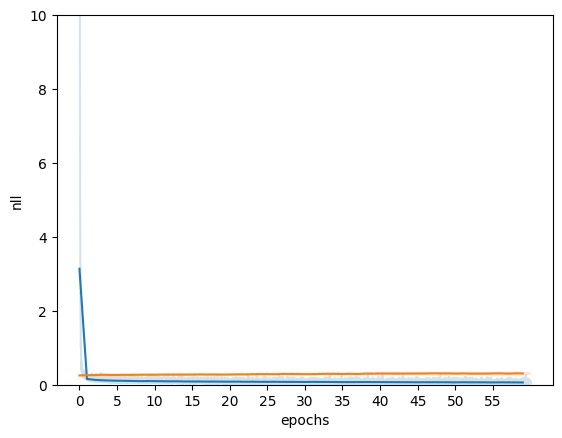

In [ ]:
# imporved mini-batch approach with scan

# Train
# lr = config['curve_params']['lr']
# iter_per_epoch_train = len(x) // BATCH_SIZE
# lr_schedule = optax.linear_onecycle_schedule(
#     epochs * iter_per_epoch_train, lr, pct_start=0.1, div_factor=10.0, final_div_factor=100.0
# )
# optimizer = optax.sgd(lr_schedule, momentum=0.9, nesterov=True)

EVAL_EVERY_N_BATCH = 20
rng_key = random.PRNGKey(0)
BATCH_SIZE = 100

optimizer = optax.adamw(config['curve_params']['lr'], weight_decay=1e-5, b1=0.7, b2=0.85)
opt_state = optimizer.init({'params': curve_params['params']})

losses = []
valid_losses = []
best_loss = np.inf
best_params = curve_params
epochs = config['curve_params']['num_epochs']

def setup_metrics(batch_size, x, target, n_samples, use_linspace=False, average=True):
            if use_linspace:
                get_t = lambda key: jnp.linspace(0, 1., n_samples)
            else:
                get_t = lambda key: random.uniform(key, (n_samples,), minval=0., maxval=1.)

            def acc_fn(rng_key, params):
                x_ = x.reshape(-1, batch_size, 32, 32, 3)
                y_ = target.reshape(-1, batch_size)

                def pred(key, data):
                    x_batch, y_batch = data

                    def eval(t):
                        logits, _ = s_model.eval(
                            params['params'], params['batch_stats'], t, x_batch)  # params, batch_stats, t, x
                        loss = jnp.mean(optax.losses.softmax_cross_entropy_with_integer_labels(
                            logits=logits, labels=y_batch))
                        acc = jnp.mean(jnp.argmax(logits, axis=-1) == y_batch)
                        return loss, acc  # mean over batch
                    key, subkey = random.split(key)

                    # draw 10 samples to approximate curve performance
                    t = get_t(subkey)
                    loss, acc = jax.vmap(eval)(t)

                    if average:
                        return key, (jnp.mean(loss), jnp.mean(acc))  # mean over samples
                    else:
                        return key, (loss, acc)  # no mean over samples

                # shape (n_data, draws, output_dim)
                rng_key, (loss, acc) = jax.lax.scan(pred, rng_key, (x_, y_))
                loss = jnp.mean(loss, axis=0)
                acc = jnp.mean(acc, axis=0)
                return loss, acc  # mean over epochs
            return acc_fn
valid_metrics_fn = setup_metrics(250, x_val, y_val, n_samples=10)


def train_batch(carry, batch):
    x_, y_, batch_idx = batch
    rng_key, params, opt_state, best_loss, best_params = carry
    rng_key, subkey = random.split(rng_key)
    loss, params, opt_state, _ = s_model.train_step(
        subkey, params, x_, y_, opt_state, optimizer)
    # validate
    # jax.debug.breakpoint()
    # jax.debug.print("repulsive force: {}", s_model.repulsive_force(params, weight=0.001))
    rng_key, valid_key = random.split(rng_key)
    # val_loss = s_model.compute_loss(
    #     subkey, params, x_val, y_val, n_samples=10)
    # best_params = jax.lax.cond(
    #     val_loss < best_loss, lambda x: params, lambda x: best_params, None)
    # best_loss = jnp.minimum(best_loss, val_loss)

    # acc, val_loss = valid_metrics_fn(valid_key, params)
    val_loss, acc = jax.lax.cond((batch_idx % EVAL_EVERY_N_BATCH) == 0, lambda x: valid_metrics_fn(
        valid_key, params), lambda x: (-jnp.inf, jnp.inf), None)
    best_params = jax.lax.cond(
        val_loss < best_loss, lambda x: params, lambda x: best_params, None)
    best_loss = jnp.minimum(best_loss, val_loss)

    return (rng_key, params, opt_state, best_loss, best_params), (loss, val_loss, acc)


@scan_tqdm(epochs)
def train(carry, epoch):
    rng_key = carry[0]
    rng_key, subkey = random.split(rng_key)
    shuffel = jax.random.permutation(subkey, jnp.arange(y.shape[0]))
    # data augmentation
    rng_key, x_ = jax.lax.scan(augment, rng_key, x)
    # x_ = x
    x_ = x_[shuffel].reshape(-1, BATCH_SIZE, 32, 32, 3)
    y_ = y[shuffel].reshape(-1, BATCH_SIZE)
    carry, (loss, val_loss, val_acc) = jax.lax.scan(
        train_batch, carry, (x_, y_, jnp.arange(x_.shape[0])))

    return carry, (loss, val_loss, val_acc)


carry = (rng_key, curve_params, opt_state, best_loss, best_params)
# for epoch in tqdm(range(epochs)):
#     rng_key = carry[0]
#     shuffel = jax.random.permutation(rng_key, jnp.arange(y.shape[0]))
#     x_ = x[shuffel].reshape(-1, batch_size, 28, 28, 1)
#     y_ = y[shuffel].reshape(-1, batch_size)
#     carry, (loss, valid_loss) = jax.lax.scan(train_batch, carry, (x_, y_))
#     losses.append(loss.mean())
#     valid_losses.append(valid_loss.mean())
carry, (losses, valid_losses, acc) = jax.lax.scan(train, carry, jnp.arange(epochs))
rng_key, params, opt_state, best_loss, best_params = carry


valid_losses = valid_losses[:, ::EVAL_EVERY_N_BATCH].repeat(
    EVAL_EVERY_N_BATCH, axis=1)[:,:valid_losses.shape[1]]
valid_acc = acc[:, ::EVAL_EVERY_N_BATCH].repeat(
    EVAL_EVERY_N_BATCH, axis=1)[:, :acc.shape[1]]
plt.plot(np.array(losses).flatten(), alpha=0.2)
plt.plot(np.arange(0, epochs*losses.shape[1], losses.shape[1]),
         np.array(losses).mean(-1), c=plt.get_cmap('tab10')(0))
plt.plot(np.array(valid_losses).flatten(), alpha=0.2)
plt.plot(np.arange(0, epochs*losses.shape[1], losses.shape[1]),
         np.array(valid_losses).mean(-1), c=plt.get_cmap('tab10')(1))
# set x ticks to epochs
plt.xticks(np.arange(
    0, epochs*losses.shape[1], losses.shape[1]*5), np.arange(0, epochs, 5))
plt.ylabel("nll")
plt.xlabel("epochs")
plt.ylim(0, 10)
params

(0.0, 0.5)

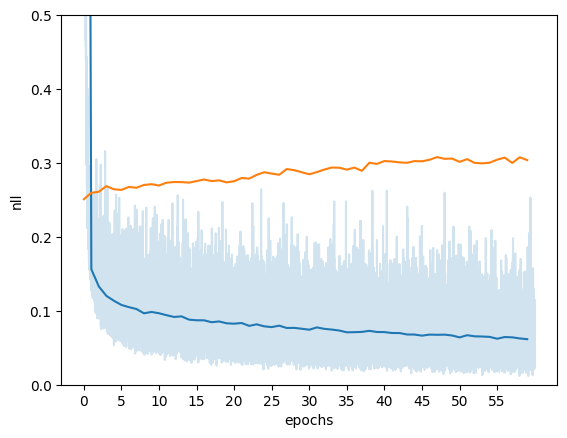

In [138]:
plt.plot(np.array(losses).flatten(), alpha=0.2)
plt.plot(np.arange(0, epochs*losses.shape[1], losses.shape[1]),
         np.array(losses).mean(-1), c=plt.get_cmap('tab10')(0))
plt.plot(np.arange(0, epochs*losses.shape[1], losses.shape[1]),
         valid_losses[jnp.isfinite(valid_losses)].reshape(epochs, -1).mean(-1), c=plt.get_cmap('tab10')(1))
# set x ticks to epochs
plt.xticks(np.arange(
    0, epochs*losses.shape[1], losses.shape[1]*5), np.arange(0, epochs, 5))
plt.ylabel("nll")
plt.xlabel("epochs")
plt.ylim(0, 0.5)

Text(0.5, 0, 'epochs')

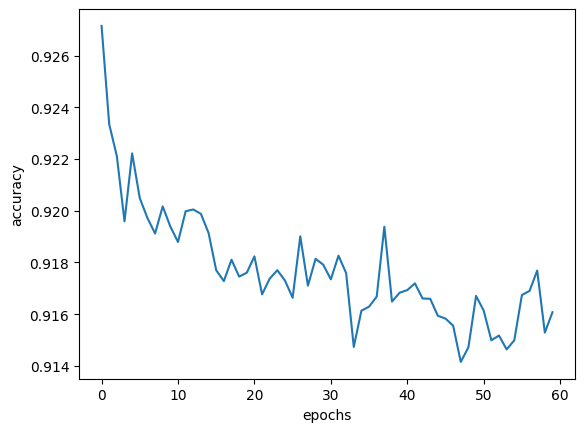

In [139]:
plt.plot(acc[jnp.isfinite(acc)].reshape(epochs, -1).mean(-1))
plt.ylabel("accuracy")
plt.xlabel("epochs")

In [140]:
acc_fn = setup_metrics(250, x_val, y_val, n_samples=10)
acc_fn(rng_key, params)

(Array(0.3073371, dtype=float32), Array(0.9158001, dtype=float32))

In [141]:
acc_fn = setup_metrics(250, x_val, y_val, n_samples=10)
acc_fn(rng_key, best_params)

(Array(0.24441445, dtype=float32), Array(0.9291001, dtype=float32))

In [142]:
acc_fn = setup_metrics(250, x_test, y_test, n_samples=20)
acc_fn(rng_key, best_params)

(Array(0.27961624, dtype=float32), Array(0.91441005, dtype=float32))

In [143]:
acc_fn = setup_metrics(250, x_test, y_test, n_samples=20)
acc_fn(rng_key, params)

(Array(0.33835334, dtype=float32), Array(0.91165507, dtype=float32))

In [144]:
from src.jax_subspace_curve import bezier_coeff_fn


# define function to compute bezier curve length
bezier_coeff_inv = bezier_coeff_fn(config['curve_params']['k'])
def get_d_bezier(t):
    coeff = jax.vmap(bezier_coeff_inv)(t)

    def clousure(cp):
        n = cp.shape[0] - 1
        cp_diff = cp[1:] - cp[:-1]
        return jnp.einsum('tj,j...->t...', coeff, cp_diff) * n
    return clousure

@jit
def bezier_length(cp):
    t = jnp.linspace(0, 1, 1000)
    d_bezier = get_d_bezier(t)
    d_t = jnp.linalg.norm(d_bezier(cp), axis=-1)
    length = jax.scipy.integrate.trapezoid(d_t, t)
    return length

In [145]:
cp = pytree_to_matrix(params['params'], config['curve_params']['k'])
print("Curve length: ", bezier_length(cp).item())

cp = pytree_to_matrix(best_params['params'], config['curve_params']['k'])
print("Curve length with best params: ", bezier_length(cp).item())

Curve length:  53.596702575683594
Curve length with best params:  0.4445453882217407


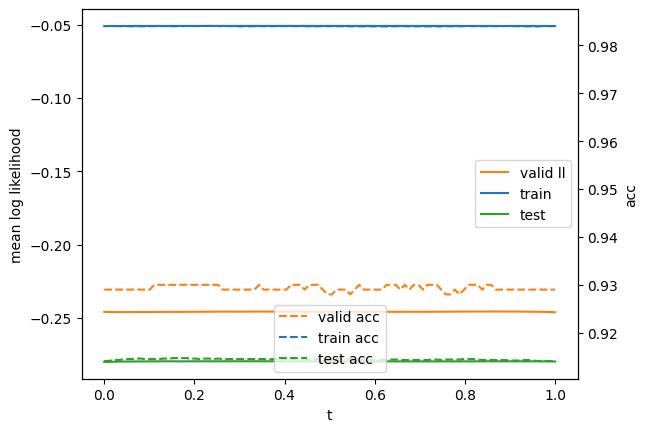

In [146]:
def setup_metrics(batch_size, x, target, n_samples, use_linspace=False, average=True):
    if use_linspace:
        def get_t(key): return jnp.linspace(0, 1., n_samples)
    else:
        def get_t(key): return random.uniform(key, (n_samples,), minval=0., maxval=1.)

    def acc_fn(rng_key, params):
        x_ = x.reshape(-1, batch_size, 32, 32, 3)
        y_ = target.reshape(-1, batch_size)

        def pred(key, data):
            x_batch, y_batch = data

            def eval(t):
                logits, _ = s_model.eval(
                    params['params'], params['batch_stats'], t, x_batch)  # params, batch_stats, t, x
                loss = jnp.mean(optax.losses.softmax_cross_entropy_with_integer_labels(
                    logits=logits, labels=y_batch))
                acc = jnp.mean(jnp.argmax(logits, axis=-1) == y_batch)
                return loss, acc  # mean over batch
            key, subkey = random.split(key)

            # draw 10 samples to approximate curve performance
            t = get_t(subkey)
            loss, acc = jax.vmap(eval)(t)

            if average:
                # mean over samples
                return key, (jnp.mean(loss), jnp.mean(acc))
            else:
                return key, (loss, acc)  # no mean over samples

        # shape (n_data, draws, output_dim)
        rng_key, (loss, acc) = jax.lax.scan(pred, rng_key, (x_, y_))
        loss = jnp.mean(loss, axis=0)
        acc = jnp.mean(acc, axis=0)
        return loss, acc  # mean over epochs
    return acc_fn

fig, ax = plt.subplots(1, 1)
t_space = jnp.linspace(0, 1, 100)
valid_metrics_fn_final = setup_metrics(100, x_val, y_val, n_samples=100, use_linspace=True, average=False)
train_metrics_fn_final = setup_metrics(100, x, y, n_samples=100, use_linspace=True, average=False)
test_metrics_fn_final = setup_metrics(100, x_test, y_test, n_samples=100, use_linspace=True, average=False)



# valid
rng_key = random.PRNGKey(0)
nll, acc = valid_metrics_fn_final(rng_key, best_params)
ax.plot(t_space, -nll, label="valid ll", c=plt.get_cmap('tab10')(1))
ax2 = ax.twinx()
ax2.plot(t_space, acc, label="valid acc",
            c=plt.get_cmap('tab10')(1), linestyle="--")
# train
nll, acc = train_metrics_fn_final(rng_key, best_params)
ax.plot(t_space, -nll, label="train", c=plt.get_cmap('tab10')(0))
ax2.plot(t_space, acc, label="train acc",
            c=plt.get_cmap('tab10')(0), linestyle="--")
# test
nll, acc = test_metrics_fn_final(rng_key, best_params)
ax.plot(t_space, -nll, label="test", c=plt.get_cmap('tab10')(2))
ax2.plot(t_space, acc, label="test acc",
            c=plt.get_cmap('tab10')(2), linestyle="--")
ax.set_xlabel("t")
ax.set_ylabel("mean log likelihood")
ax2.set_ylabel("acc")
ax.legend()
ax2.legend(loc='lower center')

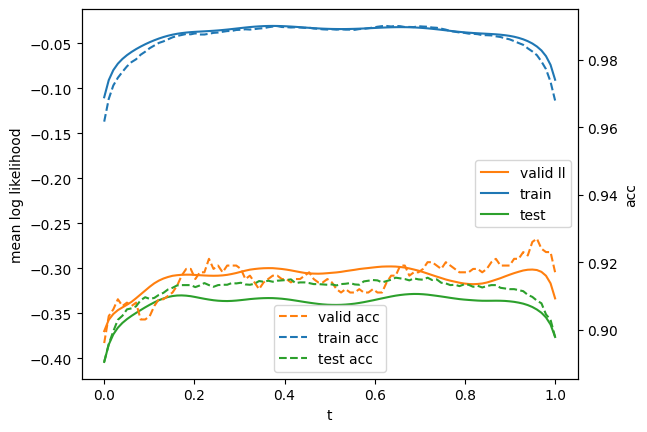

In [147]:
fig, ax = plt.subplots(1, 1)
t_space = jnp.linspace(0, 1, 100)
valid_metrics_fn_final = setup_metrics(100, x_val, y_val, n_samples=100, use_linspace=True, average=False)
train_metrics_fn_final = setup_metrics(100, x, y, n_samples=100, use_linspace=True, average=False)
test_metrics_fn_final = setup_metrics(100, x_test, y_test, n_samples=100, use_linspace=True, average=False)



# valid
rng_key = random.PRNGKey(0)
nll, acc = valid_metrics_fn_final(rng_key, params)
ax.plot(t_space, -nll, label="valid ll", c=plt.get_cmap('tab10')(1))
ax2 = ax.twinx()
ax2.plot(t_space, acc, label="valid acc",
            c=plt.get_cmap('tab10')(1), linestyle="--")
# train
nll, acc = train_metrics_fn_final(rng_key, params)
ax.plot(t_space, -nll, label="train", c=plt.get_cmap('tab10')(0))
ax2.plot(t_space, acc, label="train acc",
            c=plt.get_cmap('tab10')(0), linestyle="--")
# test
nll, acc = test_metrics_fn_final(rng_key, params)
ax.plot(t_space, -nll, label="test", c=plt.get_cmap('tab10')(2))
ax2.plot(t_space, acc, label="test acc",
            c=plt.get_cmap('tab10')(2), linestyle="--")
ax.set_xlabel("t")
ax.set_ylabel("mean log likelihood")
ax2.set_ylabel("acc")
ax.legend()
ax2.legend(loc='lower center')

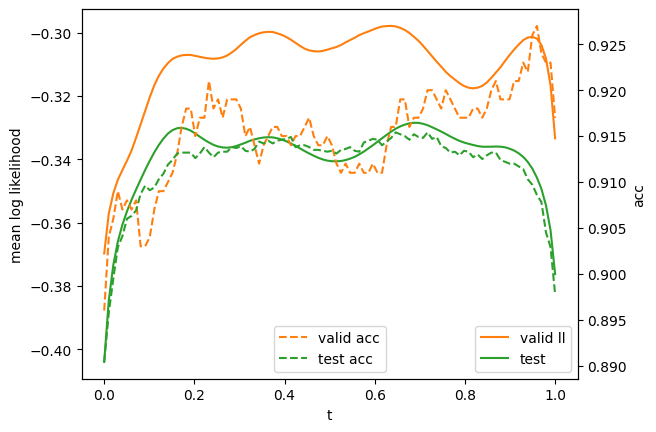

In [148]:
# valid
fig, ax = plt.subplots(1, 1)

rng_key = random.PRNGKey(0)
nll, acc = valid_metrics_fn_final(rng_key, params)
ax.plot(t_space, -nll, label="valid ll", c=plt.get_cmap('tab10')(1))
ax2 = ax.twinx()
ax2.plot(t_space, acc, label="valid acc",
            c=plt.get_cmap('tab10')(1), linestyle="--")
# test
nll, acc = test_metrics_fn_final(rng_key, params)
ax.plot(t_space, -nll, label="test", c=plt.get_cmap('tab10')(2))
ax2.plot(t_space, acc, label="test acc",
            c=plt.get_cmap('tab10')(2), linestyle="--")
ax.set_xlabel("t")
ax.set_ylabel("mean log likelihood")
ax2.set_ylabel("acc")
ax.legend()
ax2.legend(loc='lower center')

In [149]:
def single_pred(t, x, params):
    pred, stats = s_model.eval(
        params['params'], params['batch_stats'], t, x)  # params, batch_stats, t, x
    return pred

t_space = jnp.linspace(0, 1, 80)
preds = jax.vmap(single_pred, in_axes=(0, None, None))(t_space, x_val[0:50], params)
# preds = jax.nn.softmax(preds, axis=-1)
preds.shape

(80, 50, 10)

In [150]:
jnp.std(preds, axis=0).mean(0)

Array([0.7815961, 1.0643493, 0.679868 , 0.8365354, 0.8049646, 0.8364438,
       0.8389437, 0.8245784, 0.7409388, 0.9911502], dtype=float32)

Text(0.5, 0, 'classes')

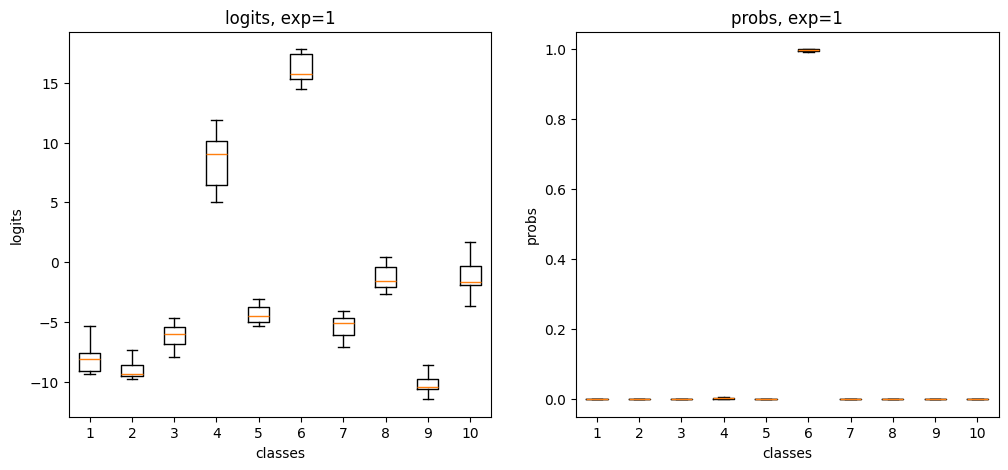

In [151]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].boxplot(preds[:, 1, :], showfliers=False)
axes[0].set_title("logits, exp=1")
axes[0].set_ylabel("logits")
axes[0].set_xlabel("classes")
axes[1].boxplot(jax.nn.softmax(preds[:, 1, :], -1), showfliers=False)
axes[1].set_title("probs, exp=1")
axes[1].set_ylabel("probs")
axes[1].set_xlabel("classes")
# plt.ylim(0.97, 1.01)

Text(0.5, 0, 'classes')

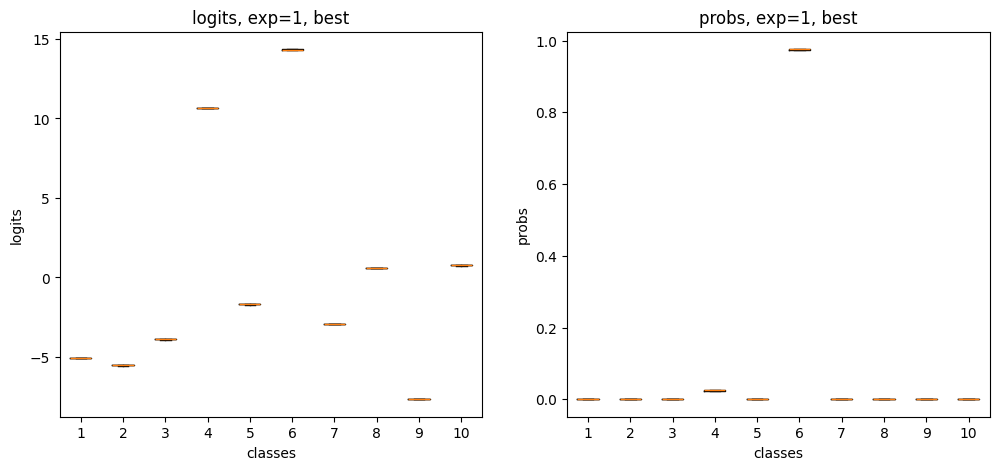

In [152]:
t_space = jnp.linspace(0, 1, 80)
preds = jax.vmap(single_pred, in_axes=(0, None, None))(t_space, x_val[0:50], best_params)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].boxplot(preds[:, 1, :], showfliers=False)
axes[0].set_title("logits, exp=1, best")
axes[0].set_ylabel("logits")
axes[0].set_xlabel("classes")
axes[1].boxplot(jax.nn.softmax(preds[:, 1, :], -1), showfliers=False)
axes[1].set_title("probs, exp=1, best")
axes[1].set_ylabel("probs")
axes[1].set_xlabel("classes")

In [ ]:
preds = jax.nn.softmax(preds, axis=-1)

### analyse from wandb test

In [5]:
from src.utils import get_params_from_run

# load params
api = wandb.Api()
# run = api.run("ddold/subspace_test/hi4dauni")
# run = api.run("ddold/subspace_test/24dp9xg8")
run = api.run("ddold/subspace_cifar/okabdx7x")
params_loaded = get_params_from_run(run, file_name_without_id="last_params.npy")
best_params_loaded = get_params_from_run(run, file_name_without_id="params.npy")
init_params_loaded = get_params_from_run(run, file_name_without_id="init_params.npy")
params_loaded

{'batch_stats': {'BatchNorm_0': {'mean': Array([-3.2195391e-03, -3.7921518e-37,  1.0240334e-02, -2.1876600e-03,
          -1.6413658e-03, -1.2939903e-03, -4.9749548e-03,  5.8331545e-03,
           5.0390321e-37,  7.8696922e-42,  3.3087048e-03, -4.3632854e-03,
           3.3953462e-42, -7.3406460e-39,  2.4238722e-35, -9.4544690e-04],      dtype=float32),
   'var': Array([5.1424938e-01, 7.0064923e-44, 4.9364021e-01, 2.2167385e-01,
          6.4153087e-01, 8.6322822e-02, 4.1028827e-01, 1.9505377e-01,
          7.0064923e-44, 7.0064923e-44, 2.1299128e-01, 4.2609972e-01,
          7.0064923e-44, 7.0064923e-44, 7.0064923e-44, 7.8300154e-01],      dtype=float32)},
  'ResNetBlock_0': {'BatchNorm_0': {'mean': Array([-1.00803816e-04,  8.99862722e-02,  2.50912458e-02,  3.73591250e-03,
           -2.77390420e-01, -1.58361688e-01, -1.06439598e-01, -4.50248346e-02,
           -3.29074353e-01, -2.56088197e-01, -1.13031320e-01, -3.82304639e-01,
           -3.57253961e-02, -1.26572773e-01, -2.70178933e

In [6]:
# load data
x, y, x_val, y_val, x_test, y_test, data_revert_norm_fn = load_cifar10(
    seed=run.config['rng_seed'])

Files already downloaded and verified
Files already downloaded and verified
Files already downloaded and verified


In [7]:
# define model
resnet20 = ResNet(num_blocks=(3, 3, 3), c_hidden=(16, 32, 64),
                  num_classes=10, act_fn=nn.relu, block_class=ResNetBlock)

s_model = CategorySubspaceBatchNorm(resnet20, k=run.config['curve_params']['k'], weight_decay=run.config['curve_params']['weight_decay'])

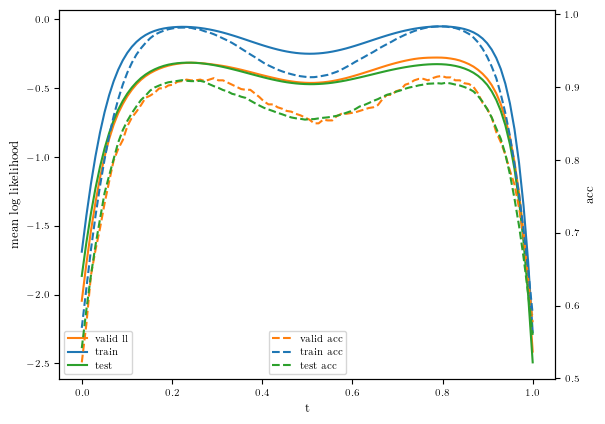

In [8]:
def setup_metrics(batch_size, x, target, n_samples, use_linspace=False, average=True):
    if use_linspace:
        def get_t(key): return jnp.linspace(0, 1., n_samples)
    else:
        def get_t(key): return random.uniform(key, (n_samples,), minval=0., maxval=1.)

    def acc_fn(rng_key, params):
        x_ = x.reshape(-1, batch_size, 32, 32, 3)
        y_ = target.reshape(-1, batch_size)

        def pred(key, data):
            x_batch, y_batch = data

            def eval(t):
                logits, _ = s_model.eval(
                    params['params'], params['batch_stats'], t, x_batch)  # params, batch_stats, t, x
                loss = jnp.mean(optax.losses.softmax_cross_entropy_with_integer_labels(
                    logits=logits, labels=y_batch))
                acc = jnp.mean(jnp.argmax(logits, axis=-1) == y_batch)
                return loss, acc  # mean over batch
            key, subkey = random.split(key)

            # draw 10 samples to approximate curve performance
            t = get_t(subkey)
            loss, acc = jax.vmap(eval)(t)

            if average:
                # mean over samples
                return key, (jnp.mean(loss), jnp.mean(acc))
            else:
                return key, (loss, acc)  # no mean over samples

        # shape (n_data, draws, output_dim)
        rng_key, (loss, acc) = jax.lax.scan(pred, rng_key, (x_, y_))
        loss = jnp.mean(loss, axis=0)
        acc = jnp.mean(acc, axis=0)
        return loss, acc  # mean over epochs
    return acc_fn

fig, ax = plt.subplots(1, 1)
t_space = jnp.linspace(0, 1, 100)
valid_metrics_fn_final = setup_metrics(100, x_val, y_val, n_samples=100, use_linspace=True, average=False)
train_metrics_fn_final = setup_metrics(100, x, y, n_samples=100, use_linspace=True, average=False)
test_metrics_fn_final = setup_metrics(100, x_test, y_test, n_samples=100, use_linspace=True, average=False)



# valid
rng_key = random.PRNGKey(0)
nll, acc = valid_metrics_fn_final(rng_key, params_loaded)
ax.plot(t_space, -nll, label="valid ll", c=plt.get_cmap('tab10')(1))
ax2 = ax.twinx()
ax2.plot(t_space, acc, label="valid acc",
            c=plt.get_cmap('tab10')(1), linestyle="--")
# train
nll, acc = train_metrics_fn_final(rng_key, params_loaded)
ax.plot(t_space, -nll, label="train", c=plt.get_cmap('tab10')(0))
ax2.plot(t_space, acc, label="train acc",
            c=plt.get_cmap('tab10')(0), linestyle="--")
# test
nll, acc = test_metrics_fn_final(rng_key, params_loaded)
ax.plot(t_space, -nll, label="test", c=plt.get_cmap('tab10')(2))
ax2.plot(t_space, acc, label="test acc",
            c=plt.get_cmap('tab10')(2), linestyle="--")
ax.set_xlabel("t")
ax.set_ylabel("mean log likelihood")
ax2.set_ylabel("acc")
ax.legend()
ax2.legend(loc='lower center')


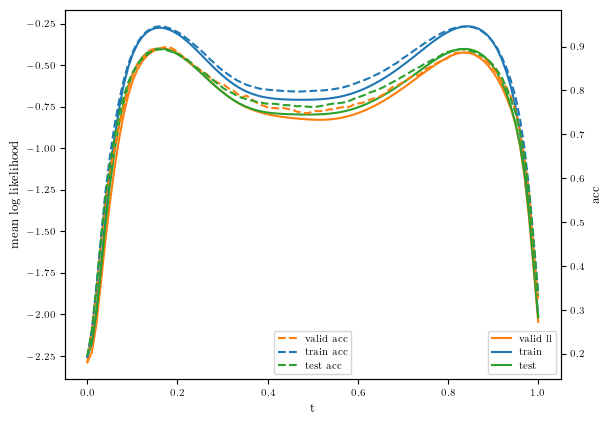

In [70]:
fig, ax = plt.subplots(1, 1)
t_space = jnp.linspace(0, 1, 100)
valid_metrics_fn_final = setup_metrics(
    100, x_val, y_val, n_samples=100, use_linspace=True, average=False)
train_metrics_fn_final = setup_metrics(
    100, x, y, n_samples=100, use_linspace=True, average=False)
test_metrics_fn_final = setup_metrics(
    100, x_test, y_test, n_samples=100, use_linspace=True, average=False)


# valid
rng_key = random.PRNGKey(0)
nll, acc = valid_metrics_fn_final(rng_key, params_loaded)
ax.plot(t_space, -nll, label="valid ll", c=plt.get_cmap('tab10')(1))
ax2 = ax.twinx()
ax2.plot(t_space, acc, label="valid acc",
         c=plt.get_cmap('tab10')(1), linestyle="--")
# train
nll, acc = train_metrics_fn_final(rng_key, params_loaded)
ax.plot(t_space, -nll, label="train", c=plt.get_cmap('tab10')(0))
ax2.plot(t_space, acc, label="train acc",
         c=plt.get_cmap('tab10')(0), linestyle="--")
# test
nll, acc = test_metrics_fn_final(rng_key, params_loaded)
ax.plot(t_space, -nll, label="test", c=plt.get_cmap('tab10')(2))
ax2.plot(t_space, acc, label="test acc",
         c=plt.get_cmap('tab10')(2), linestyle="--")
ax.set_xlabel("t")
ax.set_ylabel("mean log likelihood")
ax2.set_ylabel("acc")
ax.legend()
ax2.legend(loc='lower center')

In [139]:
params_loaded['params']['BatchNorm_0']['scale'].shape

(11, 16)

In [9]:
cp = pytree_to_matrix(params_loaded['params'], run.config['curve_params']['k'])
cp.shape

(3, 272378)

In [10]:
from src.jax_subspace_curve import bezier_coeff_fn


# define function to compute bezier curve length
bezier_coeff_inv = bezier_coeff_fn(run.config['curve_params']['k'])
def get_d_bezier(t):
    coeff = jax.vmap(bezier_coeff_inv)(t)

    def clousure(cp):
        n = cp.shape[0] - 1
        cp_diff = cp[1:] - cp[:-1]
        return jnp.einsum('tj,j...->t...', coeff, cp_diff) * n
    return clousure

@jit
def bezier_length(cp):
    t = jnp.linspace(0, 1, 1000)
    d_bezier = get_d_bezier(t)
    d_t = jnp.linalg.norm(d_bezier(cp), axis=-1)
    length = jax.scipy.integrate.trapezoid(d_t, t)
    return length

bezier_length(cp)

Array(11.172259, dtype=float32)

In [11]:
cp = pytree_to_matrix(best_params_loaded['params'], run.config['curve_params']['k'])
bezier_length(cp)

Array(14.325882, dtype=float32)

In [12]:
cp = pytree_to_matrix(
    init_params_loaded['params'], run.config['curve_params']['k'])
bezier_length(cp)

Array(71.84184, dtype=float32)

### permuation matching

In [6]:
resnet20 = ResNet(num_blocks=(3, 3, 3), c_hidden=(16, 32, 64),
                  num_classes=10, act_fn=nn.relu, block_class=ResNetBlock)

rng_key = random.PRNGKey(0)
rng_key, init_key = random.split(rng_key)
params_a = resnet20.init(init_key, x[0:2])
rng_key, init_key = random.split(rng_key)
params_b = resnet20.init(init_key, x[0:2])
params_a['params']['Conv_0']['kernel'].shape  # shape (k+1, 3, 16)

(3, 3, 3, 16)

In [17]:
for k, v in jax.tree_util.tree_flatten_with_path(params_a['params'])[0]:
    print("/".join((str(kk.key) for kk in k)), v.shape)

BatchNorm_0/bias (16,)
BatchNorm_0/scale (16,)
Conv_0/kernel (3, 3, 3, 16)
Dense_0/bias (10,)
Dense_0/kernel (64, 10)
ResNetBlock_0/BatchNorm_0/bias (16,)
ResNetBlock_0/BatchNorm_0/scale (16,)
ResNetBlock_0/BatchNorm_1/bias (16,)
ResNetBlock_0/BatchNorm_1/scale (16,)
ResNetBlock_0/Conv_0/kernel (3, 3, 16, 16)
ResNetBlock_0/Conv_1/kernel (3, 3, 16, 16)
ResNetBlock_1/BatchNorm_0/bias (16,)
ResNetBlock_1/BatchNorm_0/scale (16,)
ResNetBlock_1/BatchNorm_1/bias (16,)
ResNetBlock_1/BatchNorm_1/scale (16,)
ResNetBlock_1/Conv_0/kernel (3, 3, 16, 16)
ResNetBlock_1/Conv_1/kernel (3, 3, 16, 16)
ResNetBlock_2/BatchNorm_0/bias (16,)
ResNetBlock_2/BatchNorm_0/scale (16,)
ResNetBlock_2/BatchNorm_1/bias (16,)
ResNetBlock_2/BatchNorm_1/scale (16,)
ResNetBlock_2/Conv_0/kernel (3, 3, 16, 16)
ResNetBlock_2/Conv_1/kernel (3, 3, 16, 16)
ResNetBlock_3/BatchNorm_0/bias (32,)
ResNetBlock_3/BatchNorm_0/scale (32,)
ResNetBlock_3/BatchNorm_1/bias (32,)
ResNetBlock_3/BatchNorm_1/scale (32,)
ResNetBlock_3/Conv_0/ker

In [31]:
from flax import traverse_util
from flax.core import freeze, unfreeze


def flatten_params(params):
  return {"/".join(k): v for k, v in traverse_util.flatten_dict(unfreeze(params)).items()}


flatten_params(params_a['params'])

{'Conv_0/kernel': Array([[[[ 1.25082001e-01, -1.41821042e-01, -1.86158922e-02,
           -8.94877911e-02,  1.71241462e-01,  4.26217206e-02,
            8.82842243e-02, -1.72603786e-01,  1.12402402e-01,
           -1.37322709e-01,  1.05219912e-02, -1.47782624e-01,
            8.58851746e-02, -1.13675110e-02, -3.47781703e-02,
            5.91450185e-02],
          [ 4.24318798e-02,  2.70984530e-01,  1.86342090e-01,
           -9.57696289e-02,  3.41881104e-02,  2.16371622e-02,
           -1.30181655e-01,  5.48152961e-02, -1.38391301e-01,
           -3.13994735e-01,  1.50429741e-01, -6.21140040e-02,
            8.43527839e-02, -8.94839764e-02, -1.29117727e-01,
           -3.91761921e-02],
          [-1.42290071e-01,  3.26767750e-02, -1.72321685e-02,
           -7.23546743e-02,  1.61788747e-01,  1.02151565e-01,
           -1.80065725e-02,  2.83207983e-01, -1.11547463e-01,
           -1.49477959e-01, -1.67496665e-03, -1.09078944e-01,
           -1.31343380e-01, -4.45150249e-02, -1.43039718e

In [32]:
from src.weight_matching import permutation_spec_from_axes_to_perm, PermutationSpec

def resnet20_permutation_spec2() -> PermutationSpec:
    def conv(name, p_in, p_out): return {
        f"{name}/kernel": (None, None, p_in, p_out)}

    def norm(name, p): return {f"{name}/scale": (p, ), f"{name}/bias": (p, )}

    def dense(name, p_in, p_out): return {
        f"{name}/kernel": (p_in, p_out), f"{name}/bias": (p_out, )}
    
    def conv_bias(name, p_in, p_out): return {
        f"{name}/kernel": (None, None, p_in, p_out), f"{name}/bias": (p_out, )}

    # This is for easy blocks that use a residual connection, without any change in the number of channels.
    def easyblock(name, p): return {
        **conv(f"{name}/Conv_0", p, f"P_{name}_inner"),
        **norm(f"{name}/BatchNorm_0", f"P_{name}_inner"),
        **conv(f"{name}/Conv_1", f"P_{name}_inner", p),
        **norm(f"{name}/BatchNorm_1", p)
    }

    # This is for blocks that use a residual connection, but change the number of channels via a Conv.
    def shortcutblock(name, p_in, p_out): return {
        **conv(f"{name}/Conv_0", p_in, f"P_{name}_inner"),
        **norm(f"{name}/BatchNorm_0", f"P_{name}_inner"),
        **conv(f"{name}/Conv_1", f"P_{name}_inner", p_out),
        **norm(f"{name}/BatchNorm_1", p_out),
        **conv_bias(f"{name}/Conv_2", p_in, p_out),
    }

    return permutation_spec_from_axes_to_perm({
        **conv("Conv_0", None, "P_bg0"),
        **norm("BatchNorm_0", "P_bg0"),
        #
        **easyblock("ResNetBlock_0", "P_bg0"),
        **easyblock("ResNetBlock_1", "P_bg0"),
        **easyblock("ResNetBlock_2", "P_bg0"),
        #
        **shortcutblock("ResNetBlock_3", "P_bg0", "P_bg1"),
        **easyblock("ResNetBlock_4", "P_bg1"),
        **easyblock("ResNetBlock_5", "P_bg1"),
        #
        **shortcutblock("ResNetBlock_6", "P_bg1", "P_bg2"),
        **easyblock("ResNetBlock_7", "P_bg2"),
        **easyblock("ResNetBlock_8", "P_bg2"),
        #
        **dense("Dense_0", "P_bg2", None),
    })

In [35]:
permutation_spec = resnet20_permutation_spec2()
final_permutation = weight_matching(random.PRNGKey(0), permutation_spec,
                                    flatten_params(params_a['params']), flatten_params(params_b['params']))

0/P_ResNetBlock_4_inner: 	 10.241089
0/P_ResNetBlock_5_inner: 	 10.780869
0/P_ResNetBlock_3_inner: 	 10.466660
0/P_ResNetBlock_6_inner: 	 14.165119
0/P_ResNetBlock_0_inner: 	  6.162351
0/P_ResNetBlock_8_inner: 	 15.549362
0/P_bg0: 	  5.380852
0/P_bg1: 	  1.733032
0/P_ResNetBlock_1_inner: 	  3.435314
0/P_ResNetBlock_7_inner: 	 15.555981
0/P_ResNetBlock_2_inner: 	  3.555710
0/P_bg2: 	  1.106766
1/P_ResNetBlock_6_inner: 	  3.167160
1/P_ResNetBlock_0_inner: 	  1.504412
1/P_ResNetBlock_8_inner: 	  2.566193
1/P_bg0: 	  0.000000
1/P_bg1: 	  0.000000
1/P_ResNetBlock_3_inner: 	  2.329384
1/P_bg2: 	  0.110107
1/P_ResNetBlock_5_inner: 	  2.513119
1/P_ResNetBlock_7_inner: 	  2.432449
1/P_ResNetBlock_2_inner: 	  0.000000
1/P_ResNetBlock_1_inner: 	  0.000000
1/P_ResNetBlock_4_inner: 	  1.430332
2/P_ResNetBlock_2_inner: 	  0.000000
2/P_ResNetBlock_4_inner: 	  0.000000
2/P_ResNetBlock_5_inner: 	  0.000000
2/P_bg1: 	  0.000000
2/P_ResNetBlock_7_inner: 	  0.000000
2/P_bg2: 	  0.293167
2/P_ResNetBlock_0_

In [36]:
final_permutation

{'P_bg0': Array([ 0,  8, 15,  4,  3, 14,  6, 10, 13, 12, 11,  5,  1,  7,  9,  2],      dtype=int32),
 'P_ResNetBlock_0_inner': Array([ 8, 13, 14,  1, 11, 15,  2, 12, 10,  4,  7,  6,  5,  0,  3,  9],      dtype=int32),
 'P_ResNetBlock_1_inner': Array([ 8,  0,  4,  2,  1,  5, 14, 12,  9,  3, 10, 13, 11,  7, 15,  6],      dtype=int32),
 'P_ResNetBlock_2_inner': Array([ 8,  1, 15,  2, 11,  3,  0, 12, 14, 10,  7, 13,  4,  5,  6,  9],      dtype=int32),
 'P_ResNetBlock_3_inner': Array([ 8, 29, 21,  9, 11, 15,  3, 13, 31,  0,  4,  7, 16, 25, 14, 26, 30,
         2, 28, 23, 24,  5,  1, 10, 17, 27, 18, 19, 22,  6, 12, 20],      dtype=int32),
 'P_bg1': Array([ 0,  1,  2,  3,  4,  5,  6, 15,  8,  9,  7, 29, 12, 10, 28, 25, 14,
        22, 18, 19, 20, 21, 17, 23, 24, 11, 26, 27, 16, 13, 30, 31],      dtype=int32),
 'P_ResNetBlock_4_inner': Array([17, 11,  2, 10,  7, 19, 28, 23, 15, 20, 26, 25, 13, 29, 21,  9, 12,
        30,  3,  6, 16,  8,  1, 31, 24,  0, 14,  4,  5, 27, 22, 18],      dtype=int32

In [ ]:
# def get_permuted_param(ps: PermutationSpec, perm, k: str, params, except_axis=None):
#     """Get parameter `k` from `params`, with the permutations applied."""
#     w = params[k]
#     for axis, p in enumerate(ps.axes_to_perm[k]):
#         # Skip the axis we're trying to permute.
#         if axis == except_axis:
#             continue

#         # None indicates that there is no permutation relevant to that axis.
#         if p is not None:
#             w = jnp.take(w, perm[p], axis=axis)

#     return w

from src.weight_matching import get_permuted_param, apply_permutation


def unflatten_params(flat_params):
  return traverse_util.unflatten_dict({tuple(k.split("/")): v
                                    for k, v in flat_params.items()})

def apply_permutation(ps: PermutationSpec, perm, params):
    """Apply a `perm` to `params`."""
    return {k: get_permuted_param(ps, perm, k, params) for k in params.keys()}

In [42]:
model_b_clever = unflatten_params(
    apply_permutation(permutation_spec, final_permutation, flatten_params(params_b['params'])))

In [43]:
model_b_clever

{'Conv_0': {'kernel': Array([[[[ 1.50782257e-01, -5.36533296e-02,  1.10984445e-01,
             7.26523250e-03,  1.82773933e-01,  1.42613761e-02,
             3.09172180e-02,  2.06985429e-01, -1.34899154e-01,
             1.85267448e-01, -9.86475050e-02,  5.61720878e-02,
             1.66255876e-01,  3.70661020e-02,  5.61640412e-02,
            -8.09715390e-02],
           [ 6.92393705e-02, -3.31635471e-03,  3.30839828e-02,
            -1.98283657e-01,  2.37894937e-01, -4.90915589e-02,
            -1.07738964e-01,  3.54506299e-02,  8.32524821e-02,
             2.14372925e-03,  4.97995503e-02, -1.89356223e-01,
             5.81698194e-02,  8.34882110e-02,  1.62358657e-01,
             3.49522494e-02],
           [-2.43968517e-01, -4.44770493e-02,  8.20318609e-02,
             1.26559854e-01,  5.17414846e-02, -1.80922654e-02,
             1.35773495e-01,  1.53443828e-01, -1.24876432e-01,
             2.90497299e-02, -6.15147091e-02, -5.18388152e-02,
            -4.76917177e-02,  1.527493

#### remove permutation before subspace training

In [66]:
from src.jax_subspace_curve import CategorySubspaceBatchNorm
# define the subspace model to optimize the path
config = dict(rng_seed=4,
              curve_params=dict(k=10, lr=0.01, num_epochs=101))
BATCH_SIZE = 100
EVAL_EVERY_N_BATCH = 10

resnet20 = ResNet(num_blocks=(3, 3, 3), c_hidden=(16*4, 32*4, 64*4),
             num_classes=10, act_fn=nn.relu, block_class=ResNetBlock)
s_model = CategorySubspaceBatchNorm(
    resnet20, config['curve_params']['k'], weight_decay=0.0, perm_spec=permutation_spec)
rng_key = random.PRNGKey(0)
rng_key, init_key = random.split(rng_key)
params = s_model.init_params(init_key, x[0:10])
params['params']  # shape (k+1, 3, 16)

Remove permutation from k 1
0/P_ResNetBlock_4_inner: 	 27.202446
0/P_ResNetBlock_8_inner: 	 39.087830
0/P_ResNetBlock_5_inner: 	 24.185028
0/P_bg2: 	 51.129700
0/P_ResNetBlock_7_inner: 	 23.156525
0/P_ResNetBlock_3_inner: 	 23.244736
0/P_ResNetBlock_1_inner: 	 14.996231
0/P_ResNetBlock_2_inner: 	 15.853363
0/P_ResNetBlock_6_inner: 	 25.704285
0/P_ResNetBlock_0_inner: 	 16.050026
0/P_bg0: 	  0.219666
0/P_bg1: 	  0.000000
1/P_ResNetBlock_6_inner: 	  0.000000
1/P_ResNetBlock_5_inner: 	  0.000000
1/P_ResNetBlock_3_inner: 	  0.445374
1/P_ResNetBlock_8_inner: 	 21.038635
1/P_bg2: 	  0.000000
1/P_bg1: 	  0.000000
1/P_ResNetBlock_0_inner: 	  0.703217
1/P_ResNetBlock_1_inner: 	  0.918945
1/P_bg0: 	  0.009888
1/P_ResNetBlock_2_inner: 	  1.168633
1/P_ResNetBlock_4_inner: 	  0.000000
1/P_ResNetBlock_7_inner: 	  0.000000
2/P_ResNetBlock_5_inner: 	  0.000000
2/P_ResNetBlock_3_inner: 	  0.230377
2/P_bg0: 	  0.000000
2/P_ResNetBlock_6_inner: 	  0.000000
2/P_ResNetBlock_7_inner: 	  0.000000
2/P_ResNetB

{'BatchNorm_0': {'bias': Array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
         [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
          0.

In [50]:
params['params']['Conv_0']['kernel'].shape

(11, 3, 3, 3, 64)

In [51]:
print(resnet20.tabulate(jax.random.key(0), x[0:3],
                   compute_flops=False, compute_vjp_flops=False, console_kwargs={"width": 200}))


                                                                   ResNet Summary                                                                    
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ path                      ┃ module      ┃ inputs                       ┃ outputs              ┃ batch_stats        ┃ params                       ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│                           │ ResNet      │ float32[3,32,32,3]           │ float32[3,10]        │                    │                              │
├───────────────────────────┼─────────────┼──────────────────────────────┼──────────────────────┼────────────────────┼──────────────────────────────┤
│ Conv_0                    │ Conv        │ float32[3,32,32,3]           │ float32[3,32,32,64]  │  

  0%|          | 0/101 [00:00<?, ?it/s]

(0.0, 10.0)

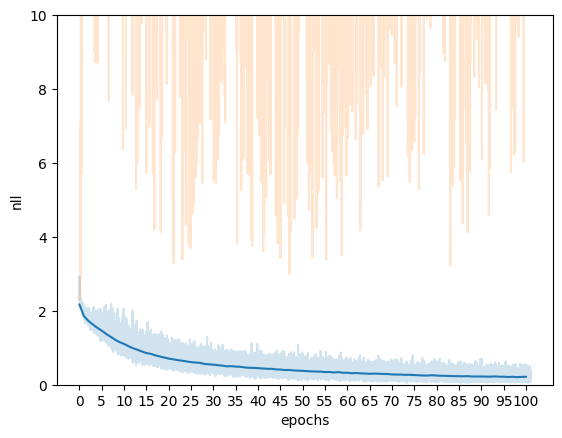

In [ ]:
# imporved mini-batch approach with scan

# Train
epochs = config['curve_params']['num_epochs']
lr = config['curve_params']['lr']
iter_per_epoch_train = len(x) // BATCH_SIZE
lr_schedule = optax.linear_onecycle_schedule(
    epochs * iter_per_epoch_train, lr, pct_start=0.1, div_factor=10.0, final_div_factor=100.0
)
optimizer = optax.sgd(lr_schedule, momentum=0.9, nesterov=True)
# optimizer = optax.adamw(config['curve_params']['lr'], weight_decay=1e-5, b1=0.7, b2=0.85)

opt_state = optimizer.init({'params': params['params']})

losses = []
valid_losses = []
best_loss = np.inf
best_params = params

def setup_metrics(batch_size, x, target, n_samples, use_linspace=False, average=True):
            if use_linspace:
                get_t = lambda key: jnp.linspace(0, 1., n_samples)
            else:
                get_t = lambda key: random.uniform(key, (n_samples,), minval=0., maxval=1.)

            def acc_fn(rng_key, params):
                x_ = x.reshape(-1, batch_size, 32, 32, 3)
                y_ = target.reshape(-1, batch_size)

                def pred(key, data):
                    x_batch, y_batch = data

                    def eval(t):
                        logits, _ = s_model.eval(
                            params['params'], params['batch_stats'], t, x_batch)  # params, batch_stats, t, x
                        loss = jnp.mean(optax.losses.softmax_cross_entropy_with_integer_labels(
                            logits=logits, labels=y_batch))
                        acc = jnp.mean(jnp.argmax(logits, axis=-1) == y_batch)
                        return loss, acc  # mean over batch
                    key, subkey = random.split(key)

                    # draw 10 samples to approximate curve performance
                    t = get_t(subkey)
                    loss, acc = jax.vmap(eval)(t)

                    if average:
                        return key, (jnp.mean(loss), jnp.mean(acc))  # mean over samples
                    else:
                        return key, (loss, acc)  # no mean over samples

                # shape (n_data, draws, output_dim)
                rng_key, (loss, acc) = jax.lax.scan(pred, rng_key, (x_, y_))
                loss = jnp.mean(loss, axis=0)
                acc = jnp.mean(acc, axis=0)
                return loss, acc  # mean over epochs
            return acc_fn
valid_metrics_fn = setup_metrics(250, x_val, y_val, n_samples=10)


def train_batch(carry, batch):
    x_, y_, batch_idx = batch
    rng_key, params, opt_state, best_loss, best_params = carry
    rng_key, subkey = random.split(rng_key)
    loss, params, opt_state, _ = s_model.train_step(
        subkey, params, x_, y_, opt_state, optimizer)
    # validate
    rng_key, valid_key = random.split(rng_key)
    # val_loss = s_model.compute_loss(
    #     subkey, params, x_val, y_val, n_samples=10)
    # best_params = jax.lax.cond(
    #     val_loss < best_loss, lambda x: params, lambda x: best_params, None)
    # best_loss = jnp.minimum(best_loss, val_loss)

    # acc, val_loss = valid_metrics_fn(valid_key, params)
    val_loss, acc = jax.lax.cond((batch_idx % 10) == 0, lambda x: valid_metrics_fn(
        valid_key, params), lambda x: (-jnp.inf, jnp.inf), None)
    best_params = jax.lax.cond(
        val_loss < best_loss, lambda x: params, lambda x: best_params, None)
    best_loss = jnp.minimum(best_loss, val_loss)

    return (rng_key, params, opt_state, best_loss, best_params), (loss, val_loss, acc)


@scan_tqdm(epochs)
def train(carry, epoch):
    rng_key = carry[0]
    rng_key, subkey = random.split(rng_key)
    shuffel = jax.random.permutation(subkey, jnp.arange(y.shape[0]))
    # data augmentation
    rng_key, x_ = jax.lax.scan(augment, rng_key, x)
    # x_ = x
    x_ = x_[shuffel].reshape(-1, BATCH_SIZE, 32, 32, 3)
    y_ = y[shuffel].reshape(-1, BATCH_SIZE)
    carry, (loss, val_loss, val_acc) = jax.lax.scan(
        train_batch, carry, (x_, y_, jnp.arange(x_.shape[0])))

    return carry, (loss, val_loss, val_acc)


carry = (rng_key, params, opt_state, best_loss, best_params)

# for epoch in tqdm(range(epochs)):
#     rng_key = carry[0]
#     shuffel = jax.random.permutation(rng_key, jnp.arange(y.shape[0]))
#     x_ = x[shuffel].reshape(-1, batch_size, 28, 28, 1)
#     y_ = y[shuffel].reshape(-1, batch_size)
#     carry, (loss, valid_loss) = jax.lax.scan(train_batch, carry, (x_, y_))
#     losses.append(loss.mean())
#     valid_losses.append(valid_loss.mean())

carry, (losses, valid_losses, acc) = jax.lax.scan(train, carry, jnp.arange(epochs))
rng_key, params, opt_state, best_loss, best_params = carry

valid_losses = valid_losses[:, ::EVAL_EVERY_N_BATCH].repeat(
    EVAL_EVERY_N_BATCH, axis=1)[:,:valid_losses.shape[1]]
valid_acc = acc[:, ::EVAL_EVERY_N_BATCH].repeat(
    EVAL_EVERY_N_BATCH, axis=1)[:, :acc.shape[1]]
plt.plot(np.array(losses).flatten(), alpha=0.2)
plt.plot(np.arange(0, epochs*losses.shape[1], losses.shape[1]),
         np.array(losses).mean(-1), c=plt.get_cmap('tab10')(0))
plt.plot(np.array(valid_losses).flatten(), alpha=0.2)
plt.plot(np.arange(0, epochs*losses.shape[1], losses.shape[1]),
         np.array(valid_losses).mean(-1), c=plt.get_cmap('tab10')(1))
# set x ticks to epochs
plt.xticks(np.arange(
    0, epochs*losses.shape[1], losses.shape[1]*5), np.arange(0, epochs, 5))
plt.ylabel("nll")
plt.xlabel("epochs")
plt.ylim(0, 10)

(0.0, 10.0)

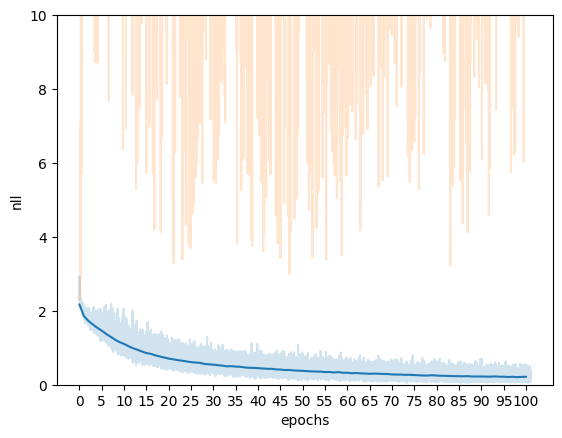

In [68]:

valid_losses = valid_losses[:, ::EVAL_EVERY_N_BATCH].repeat(
    EVAL_EVERY_N_BATCH, axis=1)[:,:valid_losses.shape[1]]

plt.plot(np.array(losses).flatten(), alpha=0.2)
plt.plot(np.arange(0, epochs*losses.shape[1], losses.shape[1]),
         np.array(losses).mean(-1), c=plt.get_cmap('tab10')(0))
plt.plot(np.array(valid_losses).flatten(), alpha=0.2)
plt.plot(np.arange(0, epochs*losses.shape[1], losses.shape[1]),
         np.array(valid_losses).mean(-1), c=plt.get_cmap('tab10')(1))
# set x ticks to epochs
plt.xticks(np.arange(
    0, epochs*losses.shape[1], losses.shape[1]*5), np.arange(0, epochs, 5))
plt.ylabel("nll")
plt.xlabel("epochs")
plt.ylim(0, 10)

Text(0.5, 0, 'epochs')

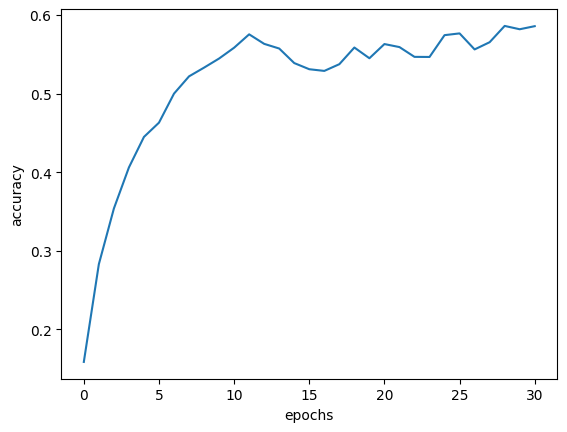

In [53]:
plt.plot(acc[jnp.isfinite(acc)].reshape(epochs, -1).mean(-1))
plt.ylabel("accuracy")
plt.xlabel("epochs")

In [54]:
acc_fn = setup_metrics(250, x_val, y_val, n_samples=10)
acc_fn(rng_key, best_params)

(Array(2213159., dtype=float32), Array(0.0928, dtype=float32))

### plain loop

490it [00:25, 19.33it/s]:00<?, ?it/s]
490it [00:21, 22.50it/s]:27<00:27, 27.02s/it]
100%|██████████| 2/2 [00:48<00:00, 24.41s/it]


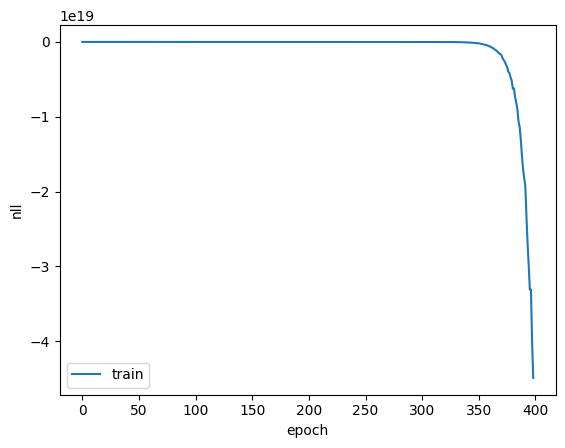

In [ ]:
config = dict(rng_seed=4,
              curve_params=dict(lr=5e-3, num_epochs=2))
batch_size = 100

rng_key = random.PRNGKey(config['rng_seed'])
rng_key, init_key = random.split(rng_key)
params = net.init(init_key, x[0:2])

# Train
lr = config['curve_params']['lr']
optimizer = optax.sgd(lr, momentum=0.9, nesterov=True)
opt_state = optimizer.init(params['params'])


losses = []
val_losses = []
best_val_loss = np.inf
best_params = None
for e in tqdm(range(config['curve_params']['num_epochs'])):
    rng_key, subkey = random.split(rng_key)
    shuffel = jax.random.permutation(subkey, jnp.arange(y.shape[0]))
    # rng_key, x_ = jax.lax.scan(augment, rng_key, x)
    x_ = x
    x_ = x_[shuffel].reshape(-1, batch_size, 32, 32, 3)
    y_ = y[shuffel].reshape(-1, batch_size)

    net_params, stats_params = params['params'], params['batch_stats']
    # train
    for xb, yb in tqdm(zip(x_, y_)):
        (loss, stats_params), grads = jax.value_and_grad(train_loss_fn, argnums=0,
                                                        has_aux=True)(net_params, stats_params, xb, yb)
        updates, opt_state = optimizer.update(grads, opt_state)
        net_params = optax.apply_updates(net_params, updates)
        losses.append(loss)

    # validate
    rng_key, subkey = random.split(rng_key)
    val_loss = [valid_loss_fn(net_params, stats_params, x_val[i *
                        250:(i+1)*250], y_val[i*250:(i+1)*250])[0] for i in range(4)]
    val_loss = jnp.mean(jnp.array(val_loss))

    params = {'params': net_params, 'batch_stats': stats_params}
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_params = params
    val_losses.append(val_loss)
    losses.append(loss)

plt.plot(losses, label='train')
# plt.plot(val_losses, label='validation')
plt.legend()
plt.ylabel("nll")
plt.xlabel("epoch")
plt.show()

### Analyse runs

In [17]:
api = wandb.Api()
results = []
# for s_id in ['vl6382k1', 'x26ip745', 'd8bi25u9']:
for s_id in ['b4iwxik8',]:
    t_bar = tqdm(api.sweep(f"ddold/cifar_PtoC/{s_id}").runs)
    t_bar.set_description(f"Sweep id: {s_id}")
    for run in t_bar:
        if (run.state == 'finished'):
            t_bar.set_postfix_str(run.name)
            res = dict(Id=run.id,
                       SubspaceDim=run.config['curve_params']['k'],
                       Seed=run.config['rng_seed'],
                       Jitter=run.config['curve_params']['jitter'],
                       Gravity=run.config['curve_params']['gravity'],
                       WeightDecay=run.config['curve_params']['weight_decay'],
                       RemoveInitialPermutation=run.config['curve_params']['remove_initial_permutation'],
                       Epochs=run.config['curve_params']['num_epochs'],
                       Lr=run.config['curve_params']['optimizer_conf']['kwargs']['learning_rate'],
                       acc_test_curve=run.summary.get('acc_test_curve', np.nan),
                       acc_test_curve_last=run.summary.get('acc_test_curve_last', np.nan),
                       acc_val_curve=run.summary.get('acc_val_curve', np.nan),
                       acc_val_curve_last=run.summary.get('acc_val_curve_last', np.nan),
                       nll_test_curve=run.summary.get('nll_test_curve', np.nan),
                       nll_test_curve_last=run.summary.get('nll_test_curve_last', np.nan),
                       nll_val_curve=run.summary.get('nll_val_curve', np.nan),
                       nll_val_curve_last=run.summary.get('nll_val_curve_last', np.nan),
                       length_best=run.summary.get('Curve length best', np.nan),
                       length_last=run.summary.get('Curve length last', np.nan),
                       )
            results.append(res)
        else:
            print(f"Encoundert problem with run {run.name}; state: {run.state}")
df = pd.DataFrame(results)
df

Sweep id: b4iwxik8:   0%|          | 0/288 [00:00<?, ?it/s, peach-sweep-281]   

Sweep id: b4iwxik8:  35%|███▌      | 101/288 [00:00<00:00, 490.15it/s, logical-sweep-179]  

Encoundert problem with run icy-sweep-270; state: crashed


Sweep id: b4iwxik8:  70%|██████▉   | 201/288 [00:00<00:00, 482.24it/s, rich-sweep-79]         

Encoundert problem with run solar-sweep-175; state: crashed


Sweep id: b4iwxik8:  87%|████████▋ | 251/288 [00:00<00:00, 475.33it/s, legendary-sweep-29]

Encoundert problem with run eager-sweep-78; state: crashed
Encoundert problem with run ethereal-sweep-72; state: crashed


Sweep id: b4iwxik8: 100%|██████████| 288/288 [00:00<00:00, 399.03it/s, graceful-sweep-1]   


,Id,SubspaceDim,Seed,Jitter,Gravity,WeightDecay,RemoveInitialPermutation,Epochs,Lr,acc_test_curve,acc_test_curve_last,acc_val_curve,acc_val_curve_last,nll_test_curve,nll_test_curve_last,nll_val_curve,nll_val_curve_last,length_best,length_last
0,vy63939m,10,1,1.000000e-08,0.01,0.0010,False,200,0.005,0.927600,0.389928,1.00000,0.38310,0.311713,4.774229,0.001880,4.742199,0.039911,11.682710
1,pfsvqzd0,10,0,1.000000e-08,0.01,0.0010,False,200,0.005,0.927578,0.372370,0.93784,0.37278,0.311766,11.776340,0.234382,11.638179,0.039818,11.753841
2,kwwjp04t,10,1,1.000000e-08,0.01,0.0001,False,200,0.005,0.927606,0.391092,1.00000,0.39156,0.311740,24.841276,0.001881,25.054377,0.039911,100.147018
3,hrai84d4,10,0,1.000000e-08,0.01,0.0001,False,200,0.005,0.927536,0.437032,0.93798,0.43494,0.311794,24.182154,0.234435,23.975790,0.039818,99.804787
4,l96twiq1,10,1,1.000000e-08,0.01,0.0000,False,200,0.005,0.927610,0.417532,1.00000,0.42086,0.311743,28.634001,0.001881,28.033852,0.039911,274.767517
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
279,v12wktbb,2,1,1.000000e-06,0.00,0.0000,False,200,0.050,0.927828,0.866854,1.00000,0.90588,0.312160,0.885968,0.001888,0.609586,0.050713,45.974533
280,tw3u1uty,2,1,1.000000e-06,0.00,0.0010,True,200,0.050,0.927972,0.397132,1.00000,0.40402,0.311975,3.508064,0.001890,3.452630,0.050712,9.365849
281,9i6mcej8,2,0,1.000000e-06,0.00,0.0000,False,200,0.050,0.927570,0.876264,0.93702,0.87636,0.310427,0.776735,0.232255,0.760146,0.013152,45.815037
282,n5qxk763,2,1,1.000000e-06,0.00,0.0001,True,200,0.050,0.927820,0.726372,1.00000,0.72248,0.312122,1.012525,0.001887,1.012875,0.050712,20.937195


In [18]:
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan]

,Id,SubspaceDim,Seed,Jitter,Gravity,WeightDecay,RemoveInitialPermutation,Epochs,Lr,acc_test_curve,acc_test_curve_last,acc_val_curve,acc_val_curve_last,nll_test_curve,nll_test_curve_last,nll_val_curve,nll_val_curve_last,length_best,length_last


In [24]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and (c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")

Unique configuartions: 
SubspaceDim [10  2]
Seed [1 0]
Jitter [1.e-08 1.e-06]
Gravity [0.01   0.0001 0.    ]
WeightDecay [0.001  0.0001 0.    ]
RemoveInitialPermutation [False  True]
Epochs [200]
Lr [0.005 0.05 ]

Experiment differs in ['SubspaceDim', 'Jitter', 'Gravity', 'WeightDecay', 'RemoveInitialPermutation', 'Lr'] configs


In [75]:
variable_idx

['SubspaceDim',
 'Jitter',
 'Gravity',
 'WeightDecay',
 'RemoveInitialPermutation',
 'Lr']

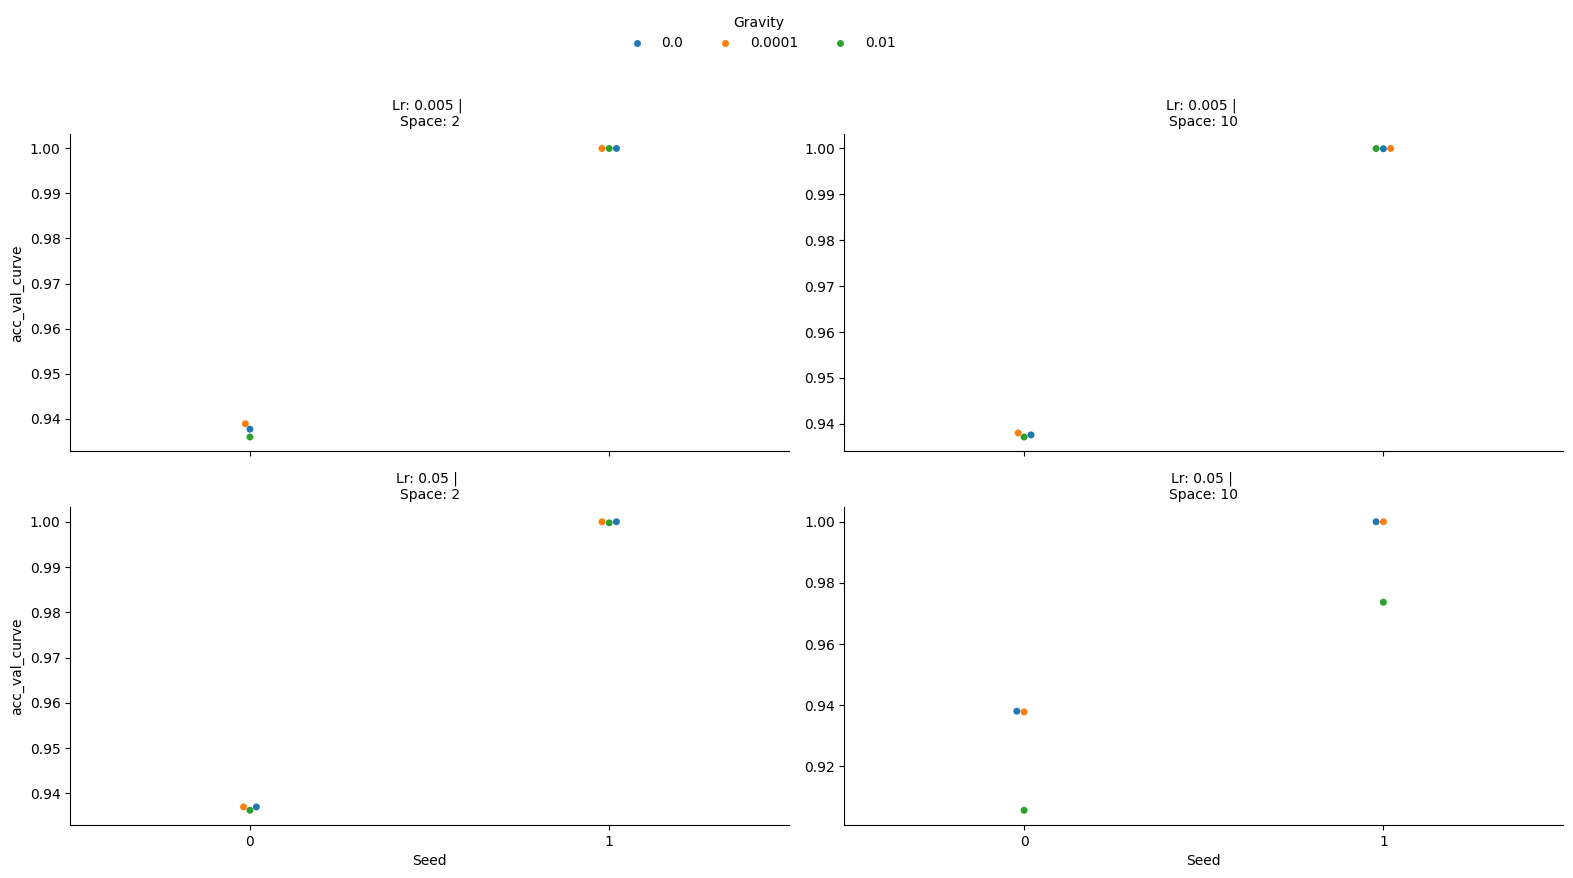

In [71]:
from matplotlib import colors
import seaborn as sns
# Seed 1 is has false dataset split

df_subset = df_clean[(df_clean['RemoveInitialPermutation'] == False) & (df_clean['Jitter'] == 1.e-06) & (df_clean['WeightDecay'] == 0.0) ]

g = sns.catplot(data=df_subset, y='acc_val_curve', x='Seed',
                col='SubspaceDim', row='Lr', kind='swarm', hue='Gravity', sharey=False, height=4, aspect=2, palette='tab10',) 
                #hue_norm=norm)
g.set_titles(row_template='Lr: {row_name}',
             col_template='\nSpace: {col_name}')
g.tight_layout()
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.1), ncols=6)

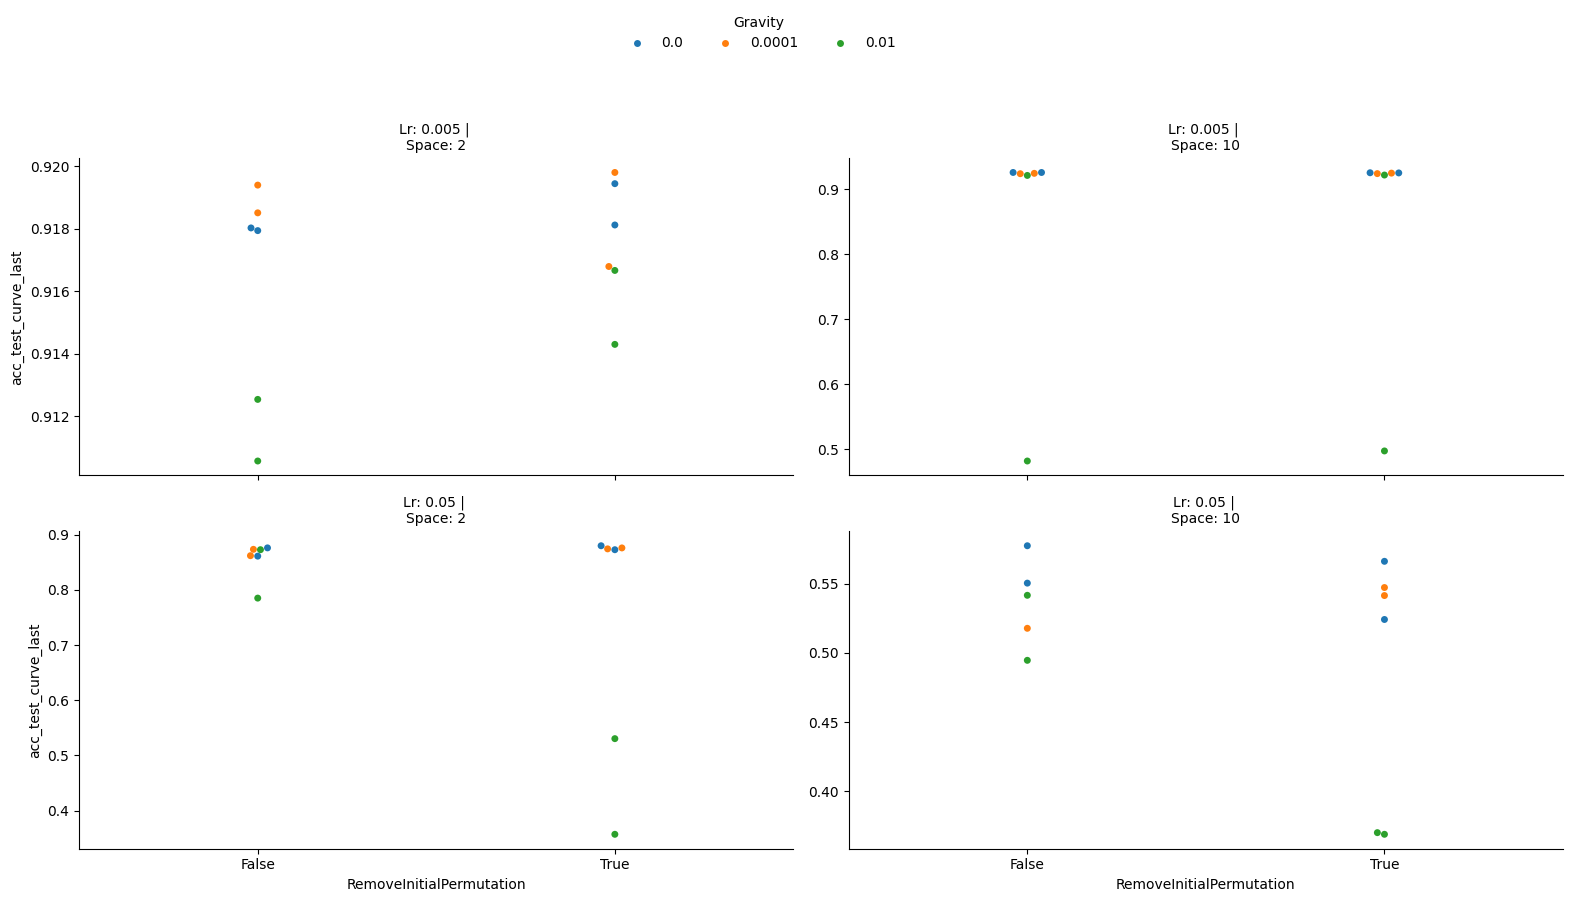

In [73]:
from matplotlib import colors
import seaborn as sns

# Remove permutation doesnet increase performance

df_subset = df_clean[ (df_clean['WeightDecay'] == 0.) & (df_clean['Seed'] == 0) & (df_clean['Jitter'] == 1e-8)]
df_subset = df_clean[ (df_clean['WeightDecay'] == 0.) & (df_clean['Seed'] == 0)]

g = sns.catplot(data=df_subset, y='acc_test_curve_last', x='RemoveInitialPermutation',
                col='SubspaceDim', row='Lr', kind='swarm', hue='Gravity', sharey=False, height=4, aspect=2, palette='tab10',) 
                #hue_norm=norm)
g.set_titles(row_template='Lr: {row_name}',
             col_template='\nSpace: {col_name}')
g.tight_layout()
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=6)

/tmp/ipykernel_152682/2715075359.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)


['Gravity' 'Jitter' 'RemoveInitialPermutation' 'WeightDecay']


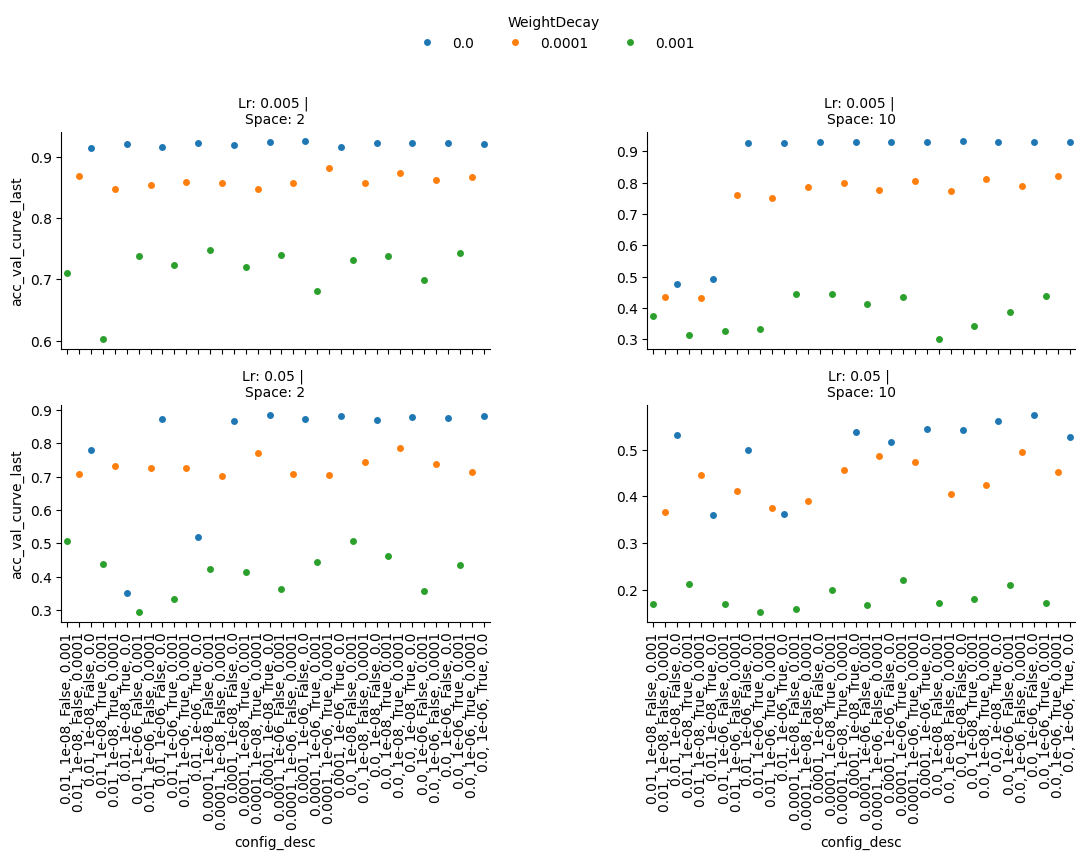

In [ ]:
from matplotlib import colors
import seaborn as sns

# Create a configuration description column based on the unique configuration columns (uppercase names)
df_subset = df_clean[(df_clean['Seed'] == 0)]
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim', 'Lr'])
df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)

g = sns.catplot(data=df_subset, y='acc_val_curve_last', x='config_desc',
                col='SubspaceDim', row='Lr', kind='swarm', hue='WeightDecay', sharey=False, height=3, aspect=2, palette='tab10')
g.set_titles(row_template='Lr: {row_name}',
             col_template='\nSpace: {col_name}')
g.tight_layout()
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=6)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)
print(desc_cols)

In [101]:
df_subset[desc_cols[::1]].astype(str).agg(', '.join, axis=1)
df_subset_sorted = df_subset.sort_values(by=desc_cols)
df_subset_sorted

,Id,SubspaceDim,Seed,Jitter,Gravity,WeightDecay,RemoveInitialPermutation,Epochs,Lr,acc_test_curve,acc_test_curve_last,acc_val_curve,acc_val_curve_last,nll_test_curve,nll_test_curve_last,nll_val_curve,nll_val_curve_last,length_best,length_last,config_desc
195,a6sgab0q,10,0,1.000000e-08,0.0000,0.000,False,200,0.005,0.927952,0.925598,0.93754,0.93126,0.309753,0.349783,0.234600,0.290678,0.113839,3.950859,"1e-08, False, 0.0, 0.0"
207,h967vxaj,10,0,1.000000e-08,0.0000,0.000,False,200,0.050,0.927588,0.550356,0.93800,0.54228,0.311681,11.312123,0.234240,11.410514,0.010684,72.378151,"1e-08, False, 0.0, 0.0"
217,0xx0wvj0,2,0,1.000000e-08,0.0000,0.000,False,200,0.005,0.926956,0.918022,0.93768,0.92240,0.310613,0.427287,0.231933,0.356905,0.122088,4.819927,"1e-08, False, 0.0, 0.0"
229,2gmj5eng,2,0,1.000000e-08,0.0000,0.000,False,200,0.050,0.927568,0.861302,0.93702,0.86854,0.310435,0.976824,0.232251,0.941328,0.013107,45.841499,"1e-08, False, 0.0, 0.0"
100,mgjnd5nb,10,0,1.000000e-08,0.0001,0.000,False,200,0.005,0.927552,0.923696,0.93800,0.92956,0.311798,0.360554,0.234407,0.295395,0.001235,7.382473,"1e-08, False, 0.0, 0.0001"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
186,pzc60p09,2,0,1.000000e-06,0.0001,0.001,True,200,0.050,0.927586,0.434208,0.93704,0.44284,0.310195,2.524013,0.231792,2.537070,0.046706,9.472963,"1e-06, True, 0.001, 0.0001"
54,2dzn2ovr,10,0,1.000000e-06,0.0100,0.001,True,200,0.005,0.922238,0.327380,0.93262,0.33260,0.241525,3.764883,0.206227,3.787294,14.392229,11.624568,"1e-06, True, 0.001, 0.01"
66,pu3e9a4d,10,0,1.000000e-06,0.0100,0.001,True,200,0.050,0.895018,0.149784,0.90334,0.15136,0.442034,122.348083,0.371694,124.118134,35.532448,15.743130,"1e-06, True, 0.001, 0.01"
78,am1bfk1u,2,0,1.000000e-06,0.0100,0.001,True,200,0.005,0.923164,0.726660,0.93182,0.72274,0.248631,0.906966,0.207947,0.927875,3.212644,6.034583,"1e-06, True, 0.001, 0.01"


/tmp/ipykernel_152682/2897130361.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)


['WeightDecay', 'Gravity', 'RemoveInitialPermutation', 'Jitter']


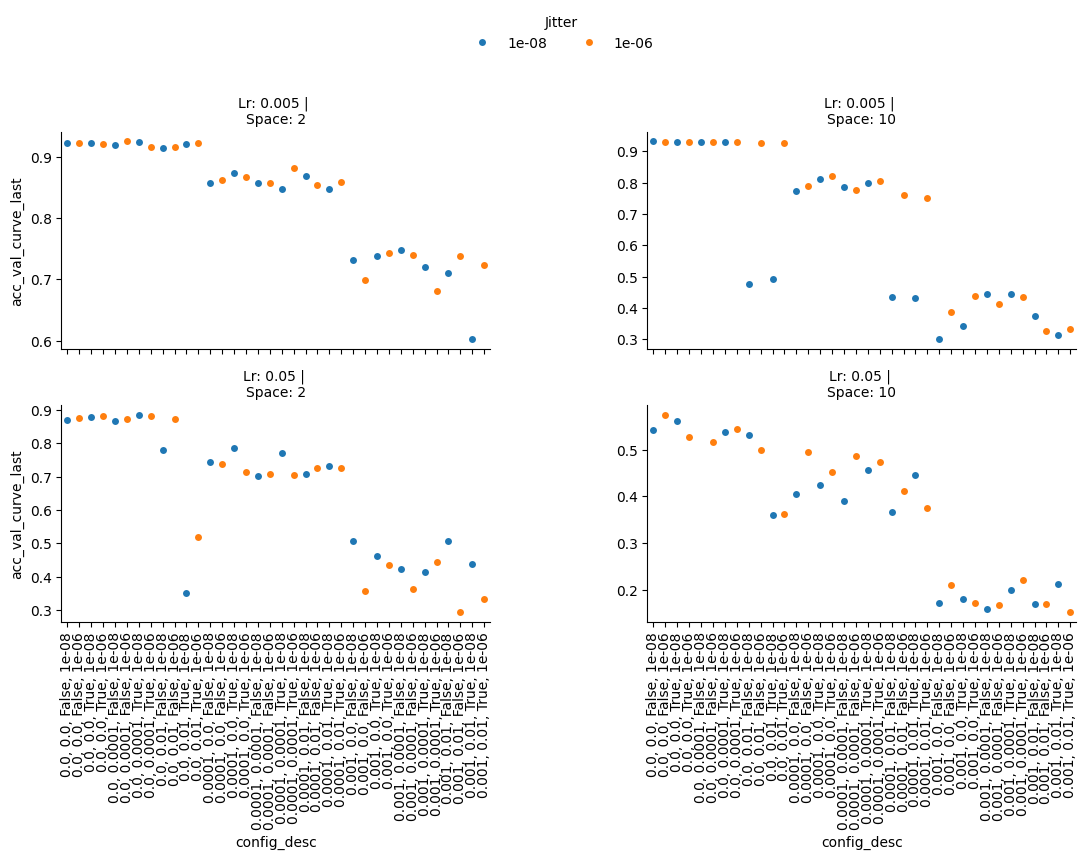

In [107]:
from matplotlib import colors
import seaborn as sns

# Create a configuration description column based on the unique configuration columns (uppercase names)
df_subset = df_clean[(df_clean['Seed'] == 0)]
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim', 'Lr'])
desc_cols = ['WeightDecay', 'Gravity', 'RemoveInitialPermutation', 'Jitter']
df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)
df_subset_sorted = df_subset.sort_values(by=desc_cols)

g = sns.catplot(data=df_subset_sorted, y='acc_val_curve_last', x='config_desc',
                col='SubspaceDim', row='Lr', kind='swarm', hue='Jitter', sharey=False, height=3, aspect=2, palette='tab10')
g.set_titles(row_template='Lr: {row_name}',
             col_template='\nSpace: {col_name}')
g.tight_layout()
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=6)
# plt.savefig('figures/subspace_toy_reg_all_temp.pdf', bbox_inches='tight')
for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)
print(desc_cols)

conclusion =>

weight_decay = 0  => increased performs



/tmp/ipykernel_152682/971385804.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)


['WeightDecay', 'Gravity', 'RemoveInitialPermutation', 'Jitter']


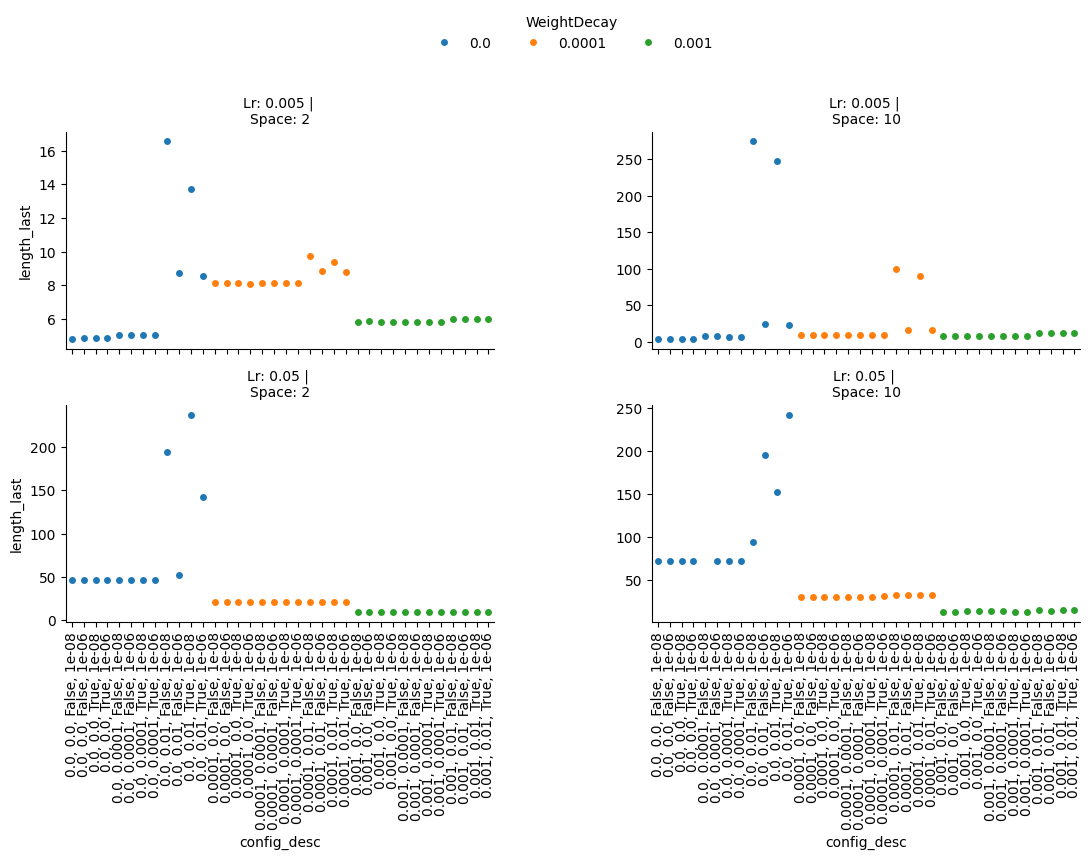

In [121]:
from matplotlib import colors
import seaborn as sns

# Create a configuration description column based on the unique configuration columns (uppercase names)
df_subset = df_clean[(df_clean['Seed'] == 0)]
desc_cols = np.setdiff1d(variable_idx, ['SubspaceDim', 'Lr'])
desc_cols = ['WeightDecay', 'Gravity', 'RemoveInitialPermutation', 'Jitter']
df_subset['config_desc'] = df_subset[desc_cols].astype(str).agg(', '.join, axis=1)
df_subset_sorted = df_subset.sort_values(by=desc_cols)

g = sns.catplot(data=df_subset_sorted, y='length_last', x='config_desc',
                col='SubspaceDim', row='Lr', kind='swarm', hue='WeightDecay', sharey=False, height=3, aspect=2, palette='tab10')
g.set_titles(row_template='Lr: {row_name}',
             col_template='\nSpace: {col_name}')
g.tight_layout()
sns.move_legend(g, loc='upper center', bbox_to_anchor=(.45, 1.13), ncols=6)

# g.set(ylim=(0, 1))

# # Add second y-axis for acc_val_curve_last
# for ax, (_, sub_df) in zip(g.axes.flatten(), df_subset_sorted.groupby(['SubspaceDim', 'Lr'])):
#     ax2 = ax.twinx()
#     # Get x positions for each config_desc
#     x_ticks = range(len(sub_df['config_desc']))
#     acc_vals = sub_df['acc_val_curve_last']
#     ax2.plot(x_ticks, acc_vals, 'ro', label='acc_val_curve_last')
#     ax2.set_ylabel('acc_val_curve_last', color='r')
#     ax2.tick_params(axis='y', labelcolor='r')
#     ax2.set_ylim(0, 1)

for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)
print(desc_cols)